In [110]:
import os
import glob
import pickle
import pandas as pd
import numpy as np
import gc
from dask.distributed import Client
from dask.diagnostics import ProgressBar
from pyscenic.prune import prune2df
from pyscenic.transform import df2regulons

from arboreto.utils import load_tf_names
from arboreto.algo import grnboost2
from ctxcore.genesig import GeneSignature
from ctxcore.rnkdb import FeatherRankingDatabase as RankingDatabase
from dask.diagnostics import ProgressBar
from pyscenic.aucell import aucell
from pyscenic.aucell import create_rankings, enrichment
from pyscenic.utils import modules_from_adjacencies, load_motifs
from pyscenic.prune import prune2df, df2regulons
from scipy.io import mmread
from scipy import sparse

import seaborn as sns
import skmisc
import pandas as pd
import sys
print(sys.executable)
print(sys.version)
import scanpy as sc
print(sc.__version__)

import attr
from collections import Counter, defaultdict
from attr import evolve
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import umap

from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests
from pyscenic.rss import regulon_specificity_scores

import matplotlib.pyplot as plt
from adjustText import adjust_text
from matplotlib.patches import Patch
from matplotlib.backends.backend_pdf import PdfPages

import anndata as ad
import igraph
import leidenalg
from sklearn.mixture import GaussianMixture

from collections import defaultdict
from functools import reduce
from ctxcore.genesig import Regulon

from importlib.metadata import version, PackageNotFoundError
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.cm as cm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.colors import TwoSlopeNorm

from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import pdist
import os, numpy as np, pandas as pd, matplotlib as mpl, matplotlib.pyplot as plt, seaborn as sns
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib.colors import TwoSlopeNorm
from matplotlib import font_manager
from matplotlib.ticker import FormatStrFormatter

/apps/z_install_tree/linux-rocky8-ivybridge/gcc-12.2.0/python-3.10.8-pmtwsrrmcmrs6olvgx5xhepgh7gl5vro/bin/python3
3.10.8 (main, Dec  5 2022, 10:38:26) [GCC 12.2.0]
1.10.4


In [2]:
celltype_palette = {"Neuroepithelium": "#fbf4deff", "Dorsal Telencephalic NPC": "#ff8e27ff", "Dorsal Telencephalic IP": "#ff5432ff", "Dorsal Telencephalic Neuron": "#f4dc4bff",
                    "Ventral Telencephalic NPC": "#d05091ff", "Ventral Telencephalic Neuron": "#6d4694ff", "Non-telencephalic NPC": "#1259b3ff", "Non-telencephalic Neuron": "#4d4ac8ff",
                    "Radial glia": "#3C8D91", "OPC": "#D66BAA", "MC": "#59A65A", "NC Derivatives": "#D94B76", "CP": "#E8A83E"}
celltype_order = ["Neuroepithelium", "Dorsal Telencephalic NPC", "Dorsal Telencephalic IP", "Dorsal Telencephalic Neuron", "Ventral Telencephalic NPC", "Ventral Telencephalic Neuron",
                  "Non-telencephalic NPC", "Non-telencephalic Neuron", "Radial glia", "OPC", "MC", "NC Derivatives", "CP"]

In [46]:
# Introducing constants
DIRECTORY = "/srv/scratch/voineagu/PROJECTS/EvaVo"

# Set Variables
protocol = "pasca"
genotype = "all" # or "wt", "ko"
integration_stage = "Preintegration" # or "Postintegration"

filename = f"{protocol}_{genotype}_{integration_stage}"

# Folders to save and set
DATA_FOLDER = os.path.join(DIRECTORY, "DATA/Extracted Lancaster Pasca")
DATABASE_FOLDER = os.path.join(DIRECTORY, "DATA/Human genome")
RESULTS_FOLDER = os.path.join(os.path.join(DIRECTORY, "RESULTS",filename))
out = "/srv/scratch/voineagu/PROJECTS/EvaVo/RESULTS/pasca_all_Preintegration/Hvg/"

DATABASES_GLOB = os.path.join(DATABASE_FOLDER,"hg38_*.genes_vs_motifs.rankings.feather")
MOTIF_ANNOTATIONS_FNAME = os.path.join(DATABASE_FOLDER, "motifs-v10-nr.hgnc-m0.00001-o0.0.tbl")
HG_TFS_FNAME = os.path.join(DATABASE_FOLDER, "allTFs_hg38.txt")
REGULONS_FNAME = os.path.join(RESULTS_FOLDER, f"regulons_{filename}.p")
MOTIFS_FNAME_HG = os.path.join(RESULTS_FOLDER, f"motifs_{filename}.csv")

# Metadata, matrix, genes, cells filepaths
counts_file = os.path.join(DATA_FOLDER, f"counts_{filename}.mtx")
genes_file = os.path.join(DATA_FOLDER, f"genes_{filename}.tsv")
barcodes_file = os.path.join(DATA_FOLDER, f"barcodes_{filename}.tsv")
metadata_file = os.path.join(DATA_FOLDER, f"metadata_{filename}.csv")

#Tfs for later
tf_categories = pd.read_csv(os.path.join(DATA_FOLDER, "brain_development_TFs.csv"))
tf_category = tf_categories.drop_duplicates("gene_symbol").set_index("gene_symbol")["category"]
tf_categories2 = pd.read_csv(os.path.join(DATA_FOLDER, "sanity_check_TFs_NPC_neuron.csv"))
tf_category2 = tf_categories2.drop_duplicates("gene_symbol").set_index("gene_symbol")["category"]

In [10]:
# Set up the metadata for later downstream filtering
metadata = pd.read_csv(metadata_file, index_col=0)
metadata["Genotype"] = np.where(metadata["orig.ident"].str.contains("KO"),"KO","WT") # Add in Genotype column for KO or WT
metadata = metadata.rename(columns={"HNOCA_annot_level_2_pruned": "CellType"}) #Renamed to CellType so it's easier later
metadata["CellType"] = metadata["CellType"].replace("Glioblast","Radial glia")
metadata["Sample"] = np.select([metadata.index.str.contains(".NG_", regex=False),metadata.index.str.contains(".JW_", regex=False)],["NG","JW"],default="UNKNOWN")

In [11]:
# Loading all motif databases for RcisTarget
def name(fname):
    return os.path.splitext(os.path.basename(fname))[0]

db_fnames = glob.glob(DATABASES_GLOB)
dbs = [RankingDatabase(fname=fname,name=name(fname))
    for fname in db_fnames]

# This is the list of all transcription factors for Mus (mouse). Downloaded from https://resources.aertslab.org/cistarget/tf_lists/
tf_names = load_tf_names(HG_TFS_FNAME)

In [12]:
# Load matrix, cells, genes
counts = mmread(counts_file).T
genes = pd.read_csv(genes_file, header=None, sep="\t").iloc[:,0].values
cells = pd.read_csv(barcodes_file, header=None, sep="\t").iloc[:,0].values
ex_matrix = pd.DataFrame.sparse.from_spmatrix(
    counts,
    index=cells,
    columns=genes)

In [13]:
# SUBSAMPLE GENES BASED ON ORIGINAL SCENIC PAPER (Genes expressed in >1% of cells, minimum total counts of 3 or more, add back all TFs)
# Number of cells
n_cells = ex_matrix.shape[0]

# 1. Genes expressed in >1% of cells
# Boolean matrix
expr_bool = (ex_matrix > 0).sparse.to_coo()
# Count cells expressing each gene
gene_detection = np.asarray(expr_bool.sum(axis=0)).flatten()
# Put back into a Series
gene_detection = pd.Series(gene_detection, index=ex_matrix.columns)

n_cells = ex_matrix.shape[0]
min_cells = int(np.ceil(0.01 * n_cells))
genes_1pct = gene_detection[gene_detection >= min_cells].index
print("Genes expressed in >=1% cells:", len(genes_1pct))
print("Genes expressed in >1% cells:", len(genes_1pct))

# 2. Minimum total counts threshold
# (same as original SCENIC: ≥3 counts)
gene_counts = ex_matrix.sum(axis=0)
genes_counts = gene_counts[gene_counts >= 3].index
print("Genes with ≥3 total counts:", len(genes_counts))

# 3. Keep genes satisfying BOTH criteria
genes_keep = set(genes_1pct).intersection(genes_counts)
print("Genes after filtering:", len(genes_keep))

# 4. Add all TFs
genes_keep.update(
    tf for tf in tf_names
    if tf in ex_matrix.columns)
print("Genes after adding TFs:", len(genes_keep))

# 5. Subset expression matrix
ex_matrix_filtered = ex_matrix[list(genes_keep)]
print(ex_matrix_filtered.shape)

# 6. TF list for GRNBoost2
tf_names_filtered = [
    tf for tf in tf_names
    if tf in ex_matrix_filtered.columns]
print("Number of TFs:", len(tf_names_filtered))

filename = f"{protocol}_{genotype}_{integration_stage}_whole_dataset"

Genes expressed in >=1% cells: 16985
Genes expressed in >1% cells: 16985
Genes with ≥3 total counts: 29733
Genes after filtering: 16985
Genes after adding TFs: 17368
(21651, 17368)
Number of TFs: 1822


In [14]:
# Creating HVGs and adding back all TFs
adata = sc.AnnData(ex_matrix_filtered)
sc.pp.highly_variable_genes(adata, flavor="seurat_v3", n_top_genes=5000)
hvg_genes = adata.var_names[adata.var["highly_variable"]].tolist()
print(f"Number of HVGs: {len(hvg_genes)}")

# Add back all the TFs
genes_keep = set(hvg_genes)
genes_keep.update(tf_names_filtered)
genes_keep = sorted(genes_keep)
print(f"Genes after adding TFs: {len(genes_keep)}")

# Final matrix to use downstream
ex_matrix_hvg = ex_matrix_filtered[genes_keep]
print("Final matrix shape:", ex_matrix_hvg.shape)

filename = f"{protocol}_{genotype}_{integration_stage}_hvg"
ex_matrix_filtered = ex_matrix_hvg

Number of HVGs: 5000
Genes after adding TFs: 6287
Final matrix shape: (21651, 6287)


In [ ]:
#1A: Run GRNBOOST2
adjacencies = grnboost2(ex_matrix_filtered, tf_names=tf_names_filtered, verbose=True)

In [ ]:
#1B: LOAD GRNBOOST2 RESULTS
adjacencies = pd.read_csv(os.path.join(RESULTS_FOLDER,f"adjacencies_{filename}.csv"))

In [ ]:
# SAVING THE OUTPUT!
adjacencies.to_csv(os.path.join(RESULTS_FOLDER,f"adjacencies_{filename}.csv"), index=False)

In [ ]:
#2A: CREATE THE MODULES
modules = list(modules_from_adjacencies(adjacencies, ex_matrix_filtered))
print(len(modules))

In [ ]:
# 2B: LOAD THE MODULES INSTEAD
with open(os.path.join(RESULTS_FOLDER, f"modules_dataset_{filename}"), "rb") as f: modules = pickle.load(f)
print(len(modules))

In [ ]:
# SAVE THE MODULES
with open(os.path.join(RESULTS_FOLDER, f"modules_dataset_{filename}"), "wb") as f: pickle.dump(modules, f)

In [ ]:
# RCISTARGET
#with ProgressBar():
#   df = prune2df(dbs, modules, MOTIF_ANNOTATIONS_FNAME)

# Do it in chunks because it tends to buckle altogether. Defragment later
chunk_size = 200
start_chunk = 0
for i in range(start_chunk, len(modules), chunk_size):
    print(f"\nProcessing modules {i} to {min(i + chunk_size, len(modules))}")
    try: client.close()
    except: pass
    client = Client(n_workers=1, threads_per_worker=1, memory_limit="4GB")
    modules_chunk = modules[i:i + chunk_size]
    try:
        with ProgressBar(): df_chunk = prune2df(dbs, modules_chunk, MOTIF_ANNOTATIONS_FNAME, client_or_address=client)
        regulons_chunk = df2regulons(df_chunk)
        output_file = os.path.join(RESULTS_FOLDER, "Chunks", f"regulons_{filename}_chunk_{i}.pkl")
        with open(output_file, "wb") as f: pickle.dump(regulons_chunk, f)
        print(f"Saved {len(regulons_chunk)} regulons to {output_file}")
        del df_chunk, regulons_chunk
        gc.collect()
    except Exception as e:
        print(f"\nChunk failed at index {i}")
        print(e)
        continue
try: client.close()
except: pass
print("\nAll chunks completed.")

In [ ]:
#COLLATING CHUNKS
regulons = []
folder = os.path.join(RESULTS_FOLDER, "Chunks")
files = sorted(f for f in os.listdir(folder) if f.startswith(f"regulons_{filename}_chunk"))
for file in files:
    with open(os.path.join(folder, file), "rb") as f: regulons.extend(pickle.load(f))
output_file = os.path.join(RESULTS_FOLDER, f"regulons_{filename}.pkl")
with open(output_file, "wb") as f: pickle.dump(regulons, f)
print("Saved regulons to:", output_file)
print("Total regulons:", len(regulons))

In [ ]:
# LOAD REGULONS
with open(os.path.join(RESULTS_FOLDER, f"regulons_{filename}.pkl"),"rb") as f: regulons = pickle.load(f)
print("Total regulons:", len(regulons))
regulons_final = regulons

In [ ]:
# Start the clustering process
# Pre-processing
# 1.1 Regulon defragmentation
# Group regulons by their underlying transcription factor
groups = defaultdict(list)
for reg in regulons_final: groups[reg.transcription_factor].append(reg)

# Merge fragments belonging to the same TF
regulons_merged, merge_report = [], []
for tf, fragments in sorted(groups.items()):
    # Multiple fragments -> merge
    merged_regulon = reduce(Regulon.union, fragments) if len(fragments) > 1 else fragments[0]
    # Single regulon -> keep unchanged
    regulons_merged.append(merged_regulon)
    fragment_sizes = [len(reg.gene2weight) for reg in fragments]
    largest_fragment = max(fragment_sizes)
    targets_after_merge = len(merged_regulon.gene2weight)
    merge_report.append({"TF": tf, "n_fragments": len(fragments), "targets_largest_fragment": largest_fragment, "targets_after_merge": targets_after_merge,
                         "targets_gained_vs_largest": targets_after_merge - largest_fragment})

# Convert report to DataFrame
merge_report = pd.DataFrame(merge_report).sort_values(["n_fragments", "targets_after_merge"], ascending=False).reset_index(drop=True)
filename = f"{filename}_defragmented"
regulons_final = regulons_merged

In [ ]:
# SAVING THE AUC MATRIX
auc_mtx = aucell(ex_matrix_filtered, regulons_final, num_workers=4)
output_path = ("/srv/scratch/voineagu/PROJECTS/EvaVo/RESULTS/pasca_all_Preintegration/Hvg/aucell_continuous_D60_285regulons_test.csv")
auc_mtx.to_csv(output_path)

In [15]:
#LOADING AUC MATRIX
auc_mtx = pd.read_csv("/srv/scratch/voineagu/PROJECTS/EvaVo/RESULTS/pasca_all_Preintegration/Hvg/aucell_continuous_D60_285regulons.csv",index_col=0)

In [64]:
# MASTER TABLE FOR REGULONS = CONTAINS FILTER REGULON PER CELL TYPE
meta = metadata.loc[auc_mtx.index].copy()
# Create CellType + Genotype group
meta["Group"] = meta["CellType"].astype(str) + "_" + meta["Genotype"].astype(str)

# 1. Calculate RSS
rss = regulon_specificity_scores(auc_mtx, meta["Group"])
# 2. Build master table
summary = []
celltypes = meta["CellType"].dropna().unique()
for celltype in celltypes:
    wt_group, ko_group = f"{celltype}_WT", f"{celltype}_KO"
    # Skip if either RSS group does not exist
    if wt_group not in rss.index or ko_group not in rss.index: continue
    wt_cells = meta.index[(meta["CellType"] == celltype) & (meta["Genotype"] == "WT")]
    ko_cells = meta.index[(meta["CellType"] == celltype) & (meta["Genotype"] == "KO")]
    # Skip if either group has no cells
    if len(wt_cells) == 0 or len(ko_cells) == 0: continue
    for regulon in rss.columns:
        rss_wt, rss_ko = rss.loc[wt_group, regulon], rss.loc[ko_group, regulon]
        wt_scores, ko_scores = auc_mtx.loc[wt_cells, regulon], auc_mtx.loc[ko_cells, regulon]
        wt_mean, ko_mean = wt_scores.mean(), ko_scores.mean()
        wt_median, ko_median = wt_scores.median(), ko_scores.median()
        delta, median_delta = ko_mean - wt_mean, ko_median - wt_median
        # Mann-Whitney U test
        statistic, pvalue = mannwhitneyu(wt_scores, ko_scores, alternative="two-sided")
        summary.append({"CellType": celltype, "Regulon": regulon, "RSS_WT": rss_wt, "RSS_KO": rss_ko, "WT_Mean": wt_mean, "KO_Mean": ko_mean, "WT_Median": wt_median, "KO_Median": ko_median,
                        "Delta_Mean": delta, "Abs_Delta_Mean": abs(delta), "Delta_Median": median_delta, "Abs_Delta_Median": abs(median_delta), "Statistic": statistic, "PValue": pvalue})

summary_cell_df = pd.DataFrame(summary)
summary_cell_df["WT_RSS_Rank"] = summary_cell_df.groupby("CellType")["RSS_WT"].rank(method="dense", ascending=False)
summary_cell_df["KO_RSS_Rank"] = summary_cell_df.groupby("CellType")["RSS_KO"].rank(method="dense", ascending=False)

# FDR correction
summary_cell_df["FDR"] = np.nan
for celltype, idx in summary_cell_df.groupby("CellType").groups.items():
    summary_cell_df.loc[idx, "FDR"] = multipletests(summary_cell_df.loc[idx, "PValue"], method="fdr_bh")[1]
summary_cell_df["Significant"] = summary_cell_df["FDR"] < 0.05
summary_cell_df = summary_cell_df.sort_values(["CellType", "WT_RSS_Rank"])
df = summary_cell_df.copy()

In [ ]:
# Saving it
output_file = os.path.join(RESULTS_FOLDER,f"Regulon_Master_Table_CellTypebased_{filename}.csv")
summary_cell_df.to_csv(output_file,index=False)

In [12]:
metadata["Geno_CellType"] = metadata["Genotype"].astype(str) + "_" + metadata["CellType"].astype(str)

def find_threshold(scores):
    """
    Determine an ON/OFF threshold for one regulon.
    Bimodal distribution: threshold = crossover between two Gaussian components
    Unimodal distribution: threshold = mean + 2 SD
    """
    x = np.asarray(scores, dtype=float)
    x = x[np.isfinite(x)]
    # Fit two-component Gaussian mixture
    gmm = GaussianMixture(n_components=2, random_state=0)
    gmm.fit(x.reshape(-1, 1))
    means, stds = gmm.means_.flatten(), np.sqrt(gmm.covariances_.flatten())
    # Order components by mean
    order = np.argsort(means)
    mu1, mu2 = means[order[0]], means[order[1]]
    sigma1, sigma2 = stds[order[0]], stds[order[1]]
    separation = abs(mu2 - mu1)
    pooled_sd = np.sqrt((sigma1**2 + sigma2**2) / 2)
    # Require reasonable separation between components
    is_bimodal = separation > pooled_sd
    if is_bimodal:
        a = 1 / (2 * sigma1**2) - 1 / (2 * sigma2**2)
        b = -mu1 / sigma1**2 + mu2 / sigma2**2
        c = mu1**2 / (2 * sigma1**2) - mu2**2 / (2 * sigma2**2) + np.log(sigma1 / sigma2)
        # Equal variance is a special case
        if abs(a) < 1e-12: threshold = -c / b
        else:
            roots = np.roots([a, b, c])
            # Choose root between the two means
            valid = [r.real for r in roots if abs(r.imag) < 1e-8 and mu1 < r.real < mu2]
            threshold = valid[0] if len(valid) > 0 else np.mean([mu1, mu2])
    else: threshold = np.mean(x) + 2 * np.std(x)
    return threshold

# BINARISE ALL REGULONS
binary_mtx = pd.DataFrame(index=auc_mtx.index, columns=auc_mtx.columns, dtype=np.int8)
thresholds = {}
for regulon in auc_mtx.columns:
    scores = auc_mtx[regulon].values
    threshold = find_threshold(scores)
    thresholds[regulon] = threshold
    binary_mtx[regulon] = (scores >= threshold).astype(np.int8)

In [13]:
threshold_df = pd.DataFrame.from_dict(thresholds,orient="index",columns=["threshold"])
threshold_df.index.name = "Regulon"
threshold_df.to_csv("/srv/scratch/voineagu/PROJECTS/EvaVo/RESULTS/pasca_all_Preintegration/Hvg/regulon_binarisation_thresholds_redone.csv")
binary_mtx.to_csv("/srv/scratch/voineagu/PROJECTS/EvaVo/RESULTS/pasca_all_Preintegration/Hvg/aucell_binary_D60_285regulons_redone.csv")

In [19]:
# load binary matrix and thresholds
threshold_df = pd.read_csv("/srv/scratch/voineagu/PROJECTS/EvaVo/RESULTS/pasca_all_Preintegration/Hvg/regulon_binarisation_thresholds_redone.csv",index_col=0)
binary_mtx = pd.read_csv("/srv/scratch/voineagu/PROJECTS/EvaVo/RESULTS/pasca_all_Preintegration/Hvg/aucell_binary_D60_285regulons_redone.csv",index_col=0)

In [15]:
# CREATION OF THE CLUSTERS
# Keep metadata in exactly the same cell order as AUCell

metadata = metadata.loc[auc_mtx.index].copy()
#auc_mtx = binary_mtx
A = ad.AnnData(auc_mtx.values.astype(np.float32),obs=metadata[["CellType", "Genotype", "Sample"]].copy())
A.var_names = [str(c).replace("(+)", "")
               for c in auc_mtx.columns]
A.obs_names = list(auc_mtx.index)
A.raw = A
# Scale each regulon so that highly variable regulons do not dominate the clustering
sc.pp.scale(A,max_value=10)
sc.pp.pca(A, n_comps=50, random_state=0)
sc.pp.neighbors(A, n_neighbors=15, n_pcs=50, random_state=0)
sc.tl.leiden(A, resolution=1, random_state=0, flavor="igraph", n_iterations=2, directed=False)
sc.tl.umap(A,random_state=0)

In [18]:
print("A shape:", A.shape)
print("Number of unique clusters:", A.obs["leiden"].nunique())

A shape: (21651, 285)
Number of unique clusters: 23


In [19]:
out = "/srv/scratch/voineagu/PROJECTS/EvaVo/RESULTS/pasca_all_Preintegration/Hvg/SCENIC_clustering_backup"
os.makedirs(out, exist_ok=True)

# Save complete clustering object
A.write_h5ad(f"{out}/SCENIC_clustering.h5ad")

# Save cluster assignments, UMAP and PCA
A.obs.to_csv(f"{out}/cluster_assignments.csv")
pd.DataFrame(A.obsm["X_umap"], index=A.obs_names,
             columns=["UMAP1", "UMAP2"]).to_csv(f"{out}/UMAP_coordinates.csv")
pd.DataFrame(A.obsm["X_pca"], index=A.obs_names).to_csv(f"{out}/PCA_coordinates.csv")

# Save package versions
packages = ["scanpy", "anndata", "numpy", "scipy", "pandas", "igraph", "leidenalg"]
versions = {"Python": sys.version}
for p in packages:
    try: versions[p] = version(p)
    except PackageNotFoundError: versions[p] = "Not installed"
json.dump(versions, open(f"{out}/package_versions.json", "w"), indent=2)

# Save clustering parameters
params = {"n_comps": 50, "n_neighbors": 15, "n_pcs": 50,
          "resolution": 1.0, "random_state": 0, "flavor": "igraph",
          "n_iterations": 2, "directed": False, "umap_random_state": 0,
          "scale_max_value": 10, "cells": A.n_obs, "regulons": A.n_vars,
          "clusters": int(A.obs["leiden"].nunique())}
json.dump(params, open(f"{out}/clustering_parameters.json", "w"), indent=2)

print(f"Saved {A.n_obs} cells and {params['clusters']} clusters to {out}")

Saved 21651 cells and 23 clusters to /srv/scratch/voineagu/PROJECTS/EvaVo/RESULTS/pasca_all_Preintegration/Hvg/SCENIC_clustering_backup


In [20]:
# LOADING A MATRIX!! 
A = sc.read_h5ad("/srv/scratch/voineagu/PROJECTS/EvaVo/RESULTS/pasca_all_Preintegration/Hvg/SCENIC_clustering_backup/SCENIC_clustering.h5ad")

In [21]:
def onoff_thresholds(auc):
    """Per-regulon on/off AUCell cutoff (SCENIC bimodal-trough principle).

    For each regulon we fit a 2-component Gaussian mixture to its AUCell
    values across all cells and take the crossover point between the low
    ("off") and high ("on") components as the threshold. Regulons that are
    essentially never active (or constant) get a threshold just above their
    max, so they cannot pass the effect floor spuriously.

    Returns a pandas Series: regulon -> threshold.
    """
    thr = {}
    for reg in auc.columns:
        x = auc[reg].values.astype(float).reshape(-1, 1)
        if np.count_nonzero(x) < 20 or x.max() == x.min():
            thr[reg] = x.max() + 1e-9
            continue
        gm = GaussianMixture(2, n_init=1, random_state=0).fit(x)
        order = np.argsort(gm.means_.ravel())          # low, high component
        lo, hi = gm.means_.ravel()[order]
        grid = np.linspace(lo, hi, 200).reshape(-1, 1)
        # first point where posterior of the HIGH component exceeds 0.5
        post_hi = gm.predict_proba(grid)[:, order[1]]
        idx = min(int(np.searchsorted(post_hi, 0.5)), 199)
        thr[reg] = float(grid[idx, 0])
    return pd.Series(thr)

def group_means_in_rest(adata, group_col):
    """Mean AUCell per group and mean over the complement, for every regulon.

    Vectorised: given a grouping (e.g. 'leiden'), returns two DataFrames
    (groups x regulons): mean_in[g, r]   = mean of regulon r over group g,
                         mean_rest[g, r] = mean of regulon r over NOT-group g.
    """
    X = pd.DataFrame(adata.X, columns=adata.var_names)
    X["_g"] = adata.obs[group_col].values
    gsum = X.groupby("_g", observed=True).sum()
    gn = X.groupby("_g", observed=True).size()
    total = gsum.sum()
    N = int(gn.sum())
    mean_in = gsum.div(gn, axis=0)
    mean_rest = (total - gsum).div(N - gn, axis=0)
    return mean_in, mean_rest
# ---------------------------------------------------------------------------
def markers_one_vs_rest(adata, group_col, thr, fdr=0.05, frac=0.5, groups=None):
    """One-vs-rest Wilcoxon markers + effect-size filter for one grouping.

    Returns a tidy DataFrame with the stats and effect columns for EVERY
    (group, regulon) pair, plus a boolean 'is_marker' applying the rule
    FDR<fdr AND (mean_in - mean_rest) >= frac * on/off_threshold.
    """
    sc.tl.rank_genes_groups(adata, group_col, method="wilcoxon",
                            groups=groups if groups else "all")
    df = sc.get.rank_genes_groups_df(adata, group=None).rename(
        columns={"group": "cluster", "names": "regulon",
                 "scores": "wilcoxon_score", "pvals_adj": "pval_adj"})
    mean_in, mean_rest = group_means_in_rest(adata, group_col)
    df["mean_in"] = [mean_in.at[c, r] for c, r in zip(df.cluster, df.regulon)]
    df["mean_rest"] = [mean_rest.at[c, r] for c, r in zip(df.cluster, df.regulon)]
    df["diff"] = df["mean_in"] - df["mean_rest"]
    df["onoff_thr"] = df["regulon"].map(thr)
    df["is_marker"] = (df["pval_adj"] < fdr) & (df["diff"] >= frac * df["onoff_thr"])
    return df

In [22]:
def main():
    ap = argparse.ArgumentParser(description=__doc__,
                                 formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--h5ad", required=True, help="AnnData with obs.leiden + obs.CellType")
    ap.add_argument("--aucell", required=True, help="continuous AUCell CSV (cells x regulons)")
    ap.add_argument("--outdir", required=True)
    ap.add_argument("--min_cells", type=int, default=20,
                    help="min cells for a cluster to be tested within a cell type")
    ap.add_argument("--fdr", type=float, default=0.05)
    ap.add_argument("--frac", type=float, default=0.5,
                    help="effect floor as a fraction of each regulon's on/off threshold")
    args = ap.parse_args()

    import os
    os.makedirs(args.outdir, exist_ok=True)

    # ---- load: obs (cluster + cell type) and the continuous AUCell matrix ----
    obs = ad.read_h5ad(args.h5ad).obs.copy()
    obs["leiden"] = obs["leiden"].astype(str)
    clusters = sorted(obs["leiden"].unique(), key=int)

    auc = pd.read_csv(args.aucell, index_col=0)
    auc.columns = [c.replace("(+)", "") for c in auc.columns]
    auc = auc.loc[obs.index]                       # align cell order to obs
    assert auc.shape[0] == obs.shape[0], "AUCell rows must match h5ad cells"

    # per-regulon on/off thresholds (computed once over all cells)
    thr = onoff_thresholds(auc)

    # build a lightweight AnnData carrying the AUCell matrix + labels
    A = ad.AnnData(auc.values.astype("float32"))
    A.var_names = list(auc.columns)
    A.obs_names = list(auc.index)
    A.obs["leiden"] = pd.Categorical(obs["leiden"].values, categories=clusters)
    A.obs["CellType"] = obs["CellType"].values

    # ---- (A) GLOBAL markers: cluster vs all other cells ----
    g = markers_one_vs_rest(A, "leiden", thr, args.fdr, args.frac)
    g[g.is_marker].to_csv(os.path.join(args.outdir, "cluster_markers_strict_global.csv"), index=False)

    # ---- (B) WITHIN-CELL-TYPE markers: cluster vs other clusters of same CT ----
    rows = []
    for ct in obs["CellType"].unique():
        sub = A[A.obs.CellType == ct].copy()
        vc = sub.obs.leiden.value_counts()
        grp = [c for c in clusters if vc.get(c, 0) >= args.min_cells]
        if len(grp) < 2:                            # need >=2 clusters to compare
            continue
        sub = sub[sub.obs.leiden.isin(grp)].copy()
        sub.obs["leiden"] = sub.obs.leiden.cat.remove_unused_categories()
        w = markers_one_vs_rest(sub, "leiden", thr, args.fdr, args.frac, groups=grp)
        w.insert(0, "CellType", ct)
        rows.append(w[w.is_marker])
    within = pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()
    within.to_csv(os.path.join(args.outdir, "cluster_markers_within_celltype.csv"), index=False)

    print(f"GLOBAL strict markers      : {int(g.is_marker.sum())}")
    print(f"WITHIN-CELL-TYPE markers   : {len(within)}")
    print(f"written to                 : {args.outdir}")

    if __name__ == "__main__":
        main()

In [22]:
# 1) Calculating Thresholds
auc = auc_mtx.copy()
thr = onoff_thresholds(auc)

In [23]:
# 2) GLOBAL MARKERS: Identifies which of the 285 regulons are specifically active in each of the 23 Leiden clusters, using all other cells as the comparison group, and then counts the number of marker regulons identified for each cluster.
marker_A = ad.AnnData(auc.loc[A.obs_names].values.astype("float32"))
marker_A.obs_names = A.obs_names
marker_A.var_names = auc.columns.astype(str)
marker_A.obs["leiden"] = (A.obs["leiden"].astype(str).values)
marker_A.obs["CellType"] = (A.obs["CellType"].astype(str).values)

global_markers = markers_one_vs_rest(marker_A,group_col="leiden",thr=thr,fdr=0.05,frac=0.5)
global_marker_regulons = global_markers[global_markers["is_marker"]].copy()
global_marker_regulons.head()
global_counts = (global_marker_regulons.groupby("cluster").size().sort_index())

/home/z5363824/.local/lib/python3.10/site-packages/scanpy/tools/_rank_genes_groups.py:429: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  self.stats[group_name, "names"] = self.var_names[global_indices]
/home/z5363824/.local/lib/python3.10/site-packages/scanpy/tools/_rank_genes_groups.py:431: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  self.stats[group_name, "scores"] = scores[global_indices]
/home/z5363824/.local/lib/python3.10/site-packages/scanpy/tools/_rank_genes_groups.py:434: PerformanceWarning: DataFrame is highly fragme

In [25]:
# SAVING GLOBAL MARKERS
global_marker_regulons.to_csv("/srv/scratch/voineagu/PROJECTS/EvaVo/RESULTS/pasca_all_Preintegration/Hvg/cluster_markers_strict_global_D60_23clusters_binarized.csv",index=False)

In [24]:
# 3) WITHIN CELL TYPE
clusters = sorted(marker_A.obs["leiden"].unique(), key=int)
rows = []
for ct in marker_A.obs["CellType"].unique():
    # Select only cells of this CellType
    sub = marker_A[marker_A.obs["CellType"] == ct].copy()
    # Number of cells from each cluster within this CellType
    vc = sub.obs["leiden"].value_counts()
    # Only test clusters with >=20 cells
    grp = [c for c in clusters if vc.get(c, 0) >= 20]
    # Need at least two clusters to make a comparison
    if len(grp) < 2: continue
    # Keep only eligible clusters
    sub = sub[sub.obs["leiden"].isin(grp)].copy()
    # Remove unused categories
    sub.obs["leiden"] = sub.obs["leiden"].astype("category")
    # Run one-vs-rest Wilcoxon within this CellType
    w = markers_one_vs_rest(sub, group_col="leiden", thr=thr, fdr=0.05, frac=0.5, groups=grp)
    # Add CellType information
    w.insert(0, "CellType", ct)
    # Keep only marker regulons
    w = w[w["is_marker"]].copy()
    rows.append(w)

within_marker_regulons = pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()

In [29]:
# Saving Within cell type marker regulons:
within_marker_regulons.to_csv("/srv/scratch/voineagu/PROJECTS/EvaVo/RESULTS/pasca_all_Preintegration/Hvg/cluster_markers_within_celltype_D60_23clusters_binarized_redone.csv",index=False)

In [28]:
# LOADING Global and Within cell type markers
within_marker_regulons = pd.read_csv("/srv/scratch/voineagu/PROJECTS/EvaVo/RESULTS/pasca_all_Preintegration/Hvg/cluster_markers_within_celltype_D60_23clusters_redone.csv",index_col=0)
global_marker_regulons = pd.read_csv("/srv/scratch/voineagu/PROJECTS/EvaVo/RESULTS/pasca_all_Preintegration/Hvg/cluster_markers_strict_global_D60_23clusters_redone.csv",index_col=0)

FileNotFoundError: [Errno 2] No such file or directory: '/srv/scratch/voineagu/PROJECTS/EvaVo/RESULTS/pasca_all_Preintegration/Hvg/cluster_markers_within_celltype_D60_23clusters_redone.csv'

In [117]:
#PAIRED TTEST
import pandas as pd, numpy as np
from scipy.stats import ttest_rel
from statsmodels.stats.multitest import multipletests

out = "/srv/scratch/voineagu/PROJECTS/EvaVo/RESULTS/pasca_all_Preintegration/Hvg/"
obs = A.obs.copy()
obs[["CellType","Sample","Genotype","leiden"]] = obs[["CellType","Sample","Genotype","leiden"]].astype(str)

counts = obs.groupby(["CellType","Sample","Genotype","leiden"]).size().rename("n").reset_index()
counts["proportion"] = counts["n"] / counts.groupby(["CellType","Sample","Genotype"])["n"].transform("sum")

results = []
for (ct, cl), g in counts.groupby(["CellType","leiden"]):
    p = g.pivot(index="Sample", columns="Genotype", values="proportion").reindex(["NG","JW"])
    if not {"WT","KO"}.issubset(p.columns) or p[["WT","KO"]].isna().any().any(): continue
    wt, ko = p["WT"].to_numpy(), p["KO"].to_numpy()
    results.append({"celltype":ct,"cluster":cl,"WT_NG":wt[0],"KO_NG":ko[0],"WT_JW":wt[1],"KO_JW":ko[1],"mean_WT":wt.mean(),"mean_KO":ko.mean(),"mean_paired_difference":(wt-ko).mean(),"p_value":ttest_rel(wt,ko).pvalue})

results = pd.DataFrame(results)
results["FDR"] = np.nan
for ct, idx in results.groupby("celltype").groups.items():
    results.loc[idx,"FDR"] = multipletests(results.loc[idx,"p_value"], method="fdr_bh")[1]

results = results.sort_values(["celltype","cluster"]).reset_index(drop=True)
results.to_csv(out+"paired_ttest_all_celltypes.csv", index=False)
results[results.p_value < 0.05].to_csv(out+"paired_ttest_significant_p005.csv", index=False)
print(f"Saved {len(results)} cell type–cluster tests; {(results.p_value < 0.05).sum()} have raw p < 0.05.")

Saved 75 cell type–cluster tests; 8 have raw p < 0.05.


In [120]:
# SCANPRO
import pandas as pd
from scanpro import scanpro

meta = A.obs[["CellType", "leiden", "Genotype", "Sample"]].copy()
meta.columns = ["celltype", "cluster", "genotype", "batch"]
meta = meta.dropna().astype(str)
meta["sample"] = meta["batch"] + "_" + meta["genotype"]
print(meta.groupby(["batch", "genotype"])["sample"].nunique())

all_results = []
for celltype in meta["celltype"].unique():
    sub = meta[meta.celltype == celltype].copy()
    if sub.genotype.nunique() != 2 or sub.cluster.nunique() < 2: continue
    try:
        result = scanpro(data=sub, clusters_col="cluster", conds_col="genotype", samples_col="sample", covariates=["batch"], conditions=["WT", "KO"], n_sims=100, seed=1, verbosity=0)
        df = result.results.reset_index().rename(columns={"clusters": "cluster"})
        df["celltype"] = celltype
        all_results.append(df)
        if celltype == "Radial glia":
            print("Design:\n", result.design)
            print(df.to_string(index=False))
    except Exception as e: print(f"Skipped {celltype}: {e}")

batch  genotype
JW     KO          1
       WT          1
NG     KO          1
       WT          1
Name: sample, dtype: int64
Design:
          WT   KO   NG
sample               
NG_WT   1.0  0.0  1.0
NG_KO   0.0  1.0  1.0
JW_WT   1.0  0.0  0.0
JW_KO   0.0  1.0  0.0
cluster  baseline_props  mean_props_WT  mean_props_KO  prop_ratio  t_statistics  p_values  adjusted_p_values    celltype
     13        0.665414       0.722242       0.495340    1.458073      0.547847  0.603564           0.603564 Radial glia
     14        0.005639       0.005927       0.004854    1.221009      0.548485  0.603153           0.603564 Radial glia
     15        0.171053       0.057688       0.490097    0.117707     -1.874426  0.110002           0.220004 Radial glia
     16        0.131579       0.179225       0.004854   36.920423      2.527995  0.044801           0.137808 Radial glia
     17        0.016917       0.020657       0.000000         inf      2.509470  0.045936           0.137808 Radial glia
     2

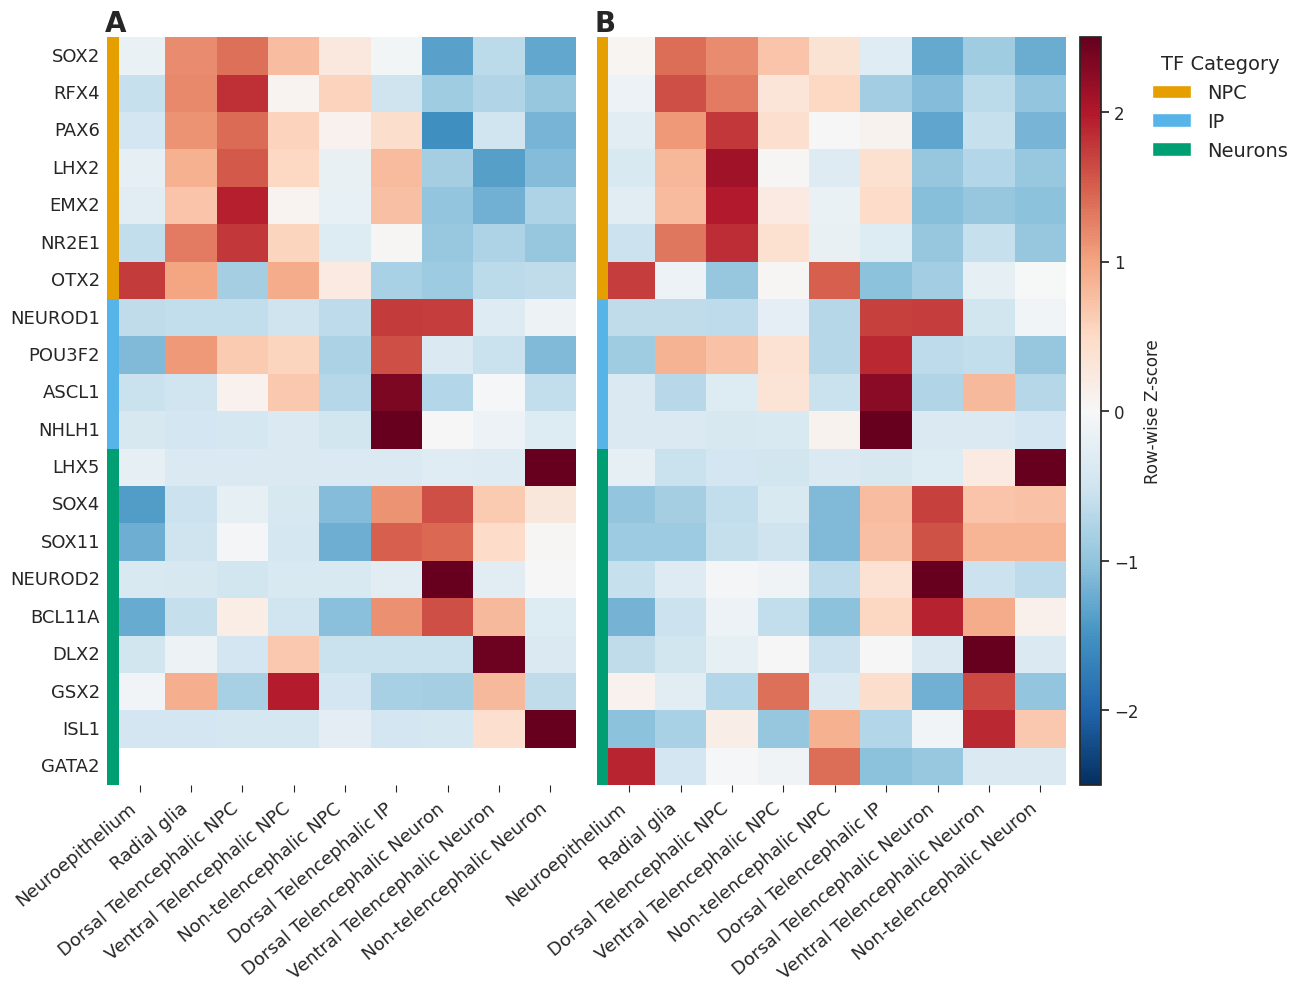

In [91]:
# PLOT 1: TF Expression vs TF Regulon activity Sanity check
# Settings
selected_tfs = ["SOX2", "RFX4", "PAX6", "LHX2", "EMX2", "NR2E1", "OTX2", "ASCL1", "NHLH1", "POU3F2", "NEUROD1", "SOX4", "SOX11", "NEUROD2", "BCL11A", "DLX2", "GSX2", "ISL1", "LHX5", "GATA2"]
celltype_order_development = ["Neuroepithelium", "Radial glia", "Dorsal Telencephalic NPC", "Ventral Telencephalic NPC", "Non-telencephalic NPC", "Dorsal Telencephalic IP",
                              "Dorsal Telencephalic Neuron", "Ventral Telencephalic Neuron", "Non-telencephalic Neuron"]
category_colours = {"NPC": "#E69F00", "transition / IP": "#56B4E9", "neurons": "#009E73"}

# Log-normalise filtered expression matrix
adata_expr = ad.AnnData(ex_matrix_filtered.copy())
sc.pp.normalize_total(adata_expr, target_sum=1e4)
sc.pp.log1p(adata_expr)
ex_matrix_lognorm = pd.DataFrame(adata_expr.X.toarray() if hasattr(adata_expr.X, "toarray") else adata_expr.X, index=ex_matrix_filtered.index, columns=ex_matrix_filtered.columns)

# Left: WT TF expression
wt_cells = metadata.index[metadata["Genotype"] == "WT"].intersection(ex_matrix_lognorm.index)
available_tfs = [tf for tf in selected_tfs if tf in ex_matrix_lognorm.columns]
expr = ex_matrix_lognorm.loc[wt_cells, available_tfs].copy()
expr["CellType"] = metadata.loc[expr.index, "CellType"]
heat_expr = expr.groupby("CellType")[available_tfs].mean().T.reindex(index=available_tfs, columns=celltype_order_development)

# Right: WT regulon activity from AUCell matrix
wt_cells = metadata.index[metadata["Genotype"] == "WT"].intersection(auc_mtx.index)
available_tfs = [tf for tf in selected_tfs if tf in ex_matrix_lognorm.columns]
auc_wt = auc_mtx.loc[wt_cells].copy()
auc_wt["CellType"] = metadata.loc[wt_cells, "CellType"]
regulon_cols = [f"{tf}(+)" for tf in available_tfs if f"{tf}(+)" in auc_mtx.columns]
heat_act = auc_wt.groupby("CellType")[regulon_cols].mean().T
heat_act.index = heat_act.index.str.replace(r"\(\+\)$", "", regex=True)
heat_act = heat_act.reindex(index=available_tfs, columns=celltype_order_development)

# Row-wise Z-score scaling
def scale_rows(data):
    sd = data.std(axis=1).replace(0, np.nan)
    return data.sub(data.mean(axis=1), axis=0).div(sd, axis=0)

heat_expr, heat_act = scale_rows(heat_expr), scale_rows(heat_act)

# Shared TF ordering by category
cats = tf_category2.reindex(selected_tfs)
order = np.argsort(pd.Categorical(cats, categories=list(category_colours), ordered=True))
heat_expr, heat_act = heat_expr.iloc[order], heat_act.iloc[order]
cats = cats.iloc[order]

# Plot side-by-side
fig, axes = plt.subplots(1, 2, figsize=(14, 11), sharey=False)
vmin, vmax = -2.5, 2.5
for ax, data, title in zip(axes, [heat_expr, heat_act], ["A", "B"]):
    sns.heatmap(data, ax=ax, cmap="RdBu_r", center=0, vmin=vmin, vmax=vmax, cbar=False, mask=data.isna(), linewidths=0)
    ax.set_title("")
    ax.text(-0.02, 1.00, title, transform=ax.transAxes, fontsize=20, ha="left", va="bottom", fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="x", bottom=True, length=5, width=0.8, pad=5)
    ax.tick_params(axis="y", left=False, length=5, width=0.8, pad=5)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha="right", fontsize=13)
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=13)
    for i, cat in enumerate(cats):
        if pd.notna(cat) and cat in category_colours:
            ax.add_patch(plt.Rectangle((-0.015, i), 0.025, 1, transform=ax.get_yaxis_transform(), color=category_colours[cat], clip_on=False, linewidth=0))

# Remove y-axis labels and tick marks from second heatmap
axes[1].set_ylabel("")
axes[1].tick_params(axis="y", left=False, labelleft=False)

# Shared colour bar, placed in its own axis
sm = plt.cm.ScalarMappable(norm=TwoSlopeNorm(vmin=vmin, vcenter=0, vmax=vmax), cmap="RdBu_r")
sm.set_array([])
cbar_ax = fig.add_axes([0.81, 0.22, 0.015, 0.68])
cbar = fig.colorbar(sm, cax=cbar_ax)
cbar.set_label("Row-wise Z-score", fontsize=12)
cbar.ax.tick_params(labelsize=12)
fig.subplots_adjust(left=0.12, right=0.98, bottom=0.22, top=0.88, wspace=0.20)

# TF category legend — display labels only
legend_labels = {"transition / IP": "IP", "neurons": "Neurons"}
fig.legend(handles=[Patch(facecolor=c, label=legend_labels.get(k, k)) for k, c in category_colours.items()], title="TF Category", loc="upper center", bbox_to_anchor=(0.91, 0.9),
           ncol=1, frameon=False, fontsize=14, title_fontsize=14)
fig.subplots_adjust(left=0.12, right=0.80, bottom=0.22, top=0.90, wspace=0.06)
plt.savefig(out + f"TF_expression_vs_TF_regulon_activity.png", dpi=300, bbox_inches="tight")
plt.show()

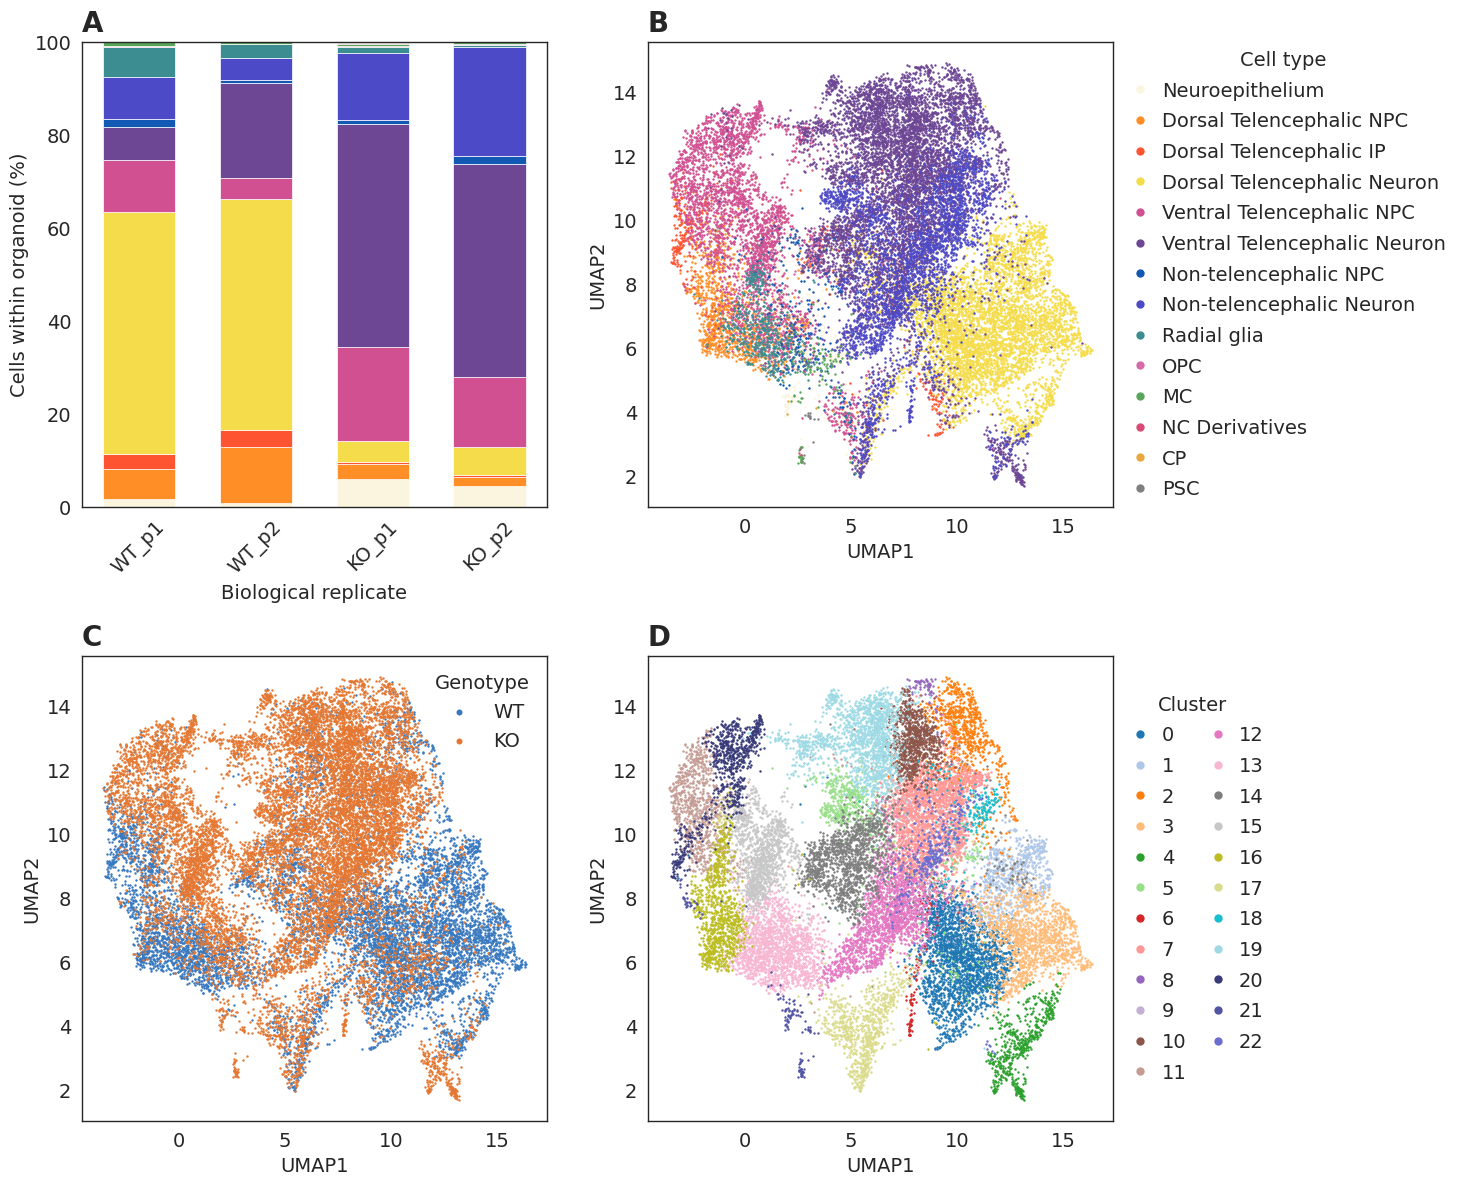

In [87]:
# PLOT 2: Cellular landscape overall
# Plotting 4 figures for the paper
U=A.obsm["X_umap"]; celltypes=A.obs["CellType"].astype(str); geno=A.obs["Genotype"].astype(str).str.upper(); clusters=A.obs["leiden"].astype(str)
celltype_order=["Neuroepithelium","Dorsal Telencephalic NPC","Dorsal Telencephalic IP","Dorsal Telencephalic Neuron","Ventral Telencephalic NPC",
                "Ventral Telencephalic Neuron","Non-telencephalic NPC","Non-telencephalic Neuron","Radial glia","OPC","MC","NC Derivatives","CP"]
cts=[ct for ct in celltype_order if ct in celltypes.unique()]; cts += [ct for ct in celltypes.unique() if ct not in cts]
ct_pal={ct:celltype_palette.get(ct,"#808080") for ct in cts}
clusters_sorted=sorted(clusters.unique(),key=int); cpal={cl:cm.tab20(i%20) if i<20 else cm.tab20b((i-20)%20) for i,cl in enumerate(clusters_sorted)}

fig,axs=plt.subplots(2,2,figsize=(20,13)); fig.subplots_adjust(left=0.08,right=0.62,bottom=0.07,top=0.90,wspace=0.1,hspace=0.32)
(ax_c,ax_a),(ax_b,ax_d)=axs

# A: Cell-type UMAP
for ct in cts:
    m=(celltypes==ct).to_numpy(); ax_a.scatter(U[m,0],U[m,1],s=3,c=[ct_pal[ct]],linewidths=0,rasterized=True)
ax_a.set(xlabel="UMAP1",ylabel="UMAP2"); ax_a.set_box_aspect(1)
ax_a.legend(handles=[Line2D([0],[0],marker="o",linestyle="",markerfacecolor=ct_pal[ct],markeredgecolor="none",markersize=6,label=ct) for ct in cts],title="Cell type",
            loc="center left",bbox_to_anchor=(0.98,0.5),frameon=False,fontsize=14,title_fontsize=14,labelspacing=0.6, handletextpad=0.1)

# C: Genotype UMAP
geno_pal={"WT":"#3778bf","KO":"#e47732"}
for g in ["WT","KO"]:
    m=(geno==g).to_numpy(); ax_b.scatter(U[m,0],U[m,1],s=3,c=geno_pal[g],linewidths=0,rasterized=True,label=g)
ax_b.set(xlabel="UMAP1",ylabel="UMAP2"); ax_b.set_box_aspect(1)
ax_b.legend(title="Genotype",loc="upper right",frameon=False,fontsize=14,title_fontsize=14,markerscale=2.5)

# B: Cell-type composition by genotype
sample_order=["WT_p1","WT_p2","KO_p1","KO_p2"]
meta=metadata.copy(); meta.index=meta.index.astype(str)
meta["Sample_label"]=np.select([meta["orig.ident"].astype(str).str.startswith("p1")&meta["Genotype"].astype(str).eq("WT"),meta["orig.ident"].astype(str).str.startswith("p2")&meta["Genotype"].astype(str).eq("WT"),meta["orig.ident"].astype(str).str.startswith("p1")&meta["Genotype"].astype(str).eq("KO"),meta["orig.ident"].astype(str).str.startswith("p2")&meta["Genotype"].astype(str).eq("KO")],sample_order,default="UNKNOWN")
meta["CellType"]=A.obs["CellType"].reindex(meta.index)
meta=meta[meta["Sample_label"].isin(sample_order)].dropna(subset=["CellType"])
counts=pd.crosstab(meta["Sample_label"],meta["CellType"]); props=counts.div(counts.sum(axis=1),axis=0)*100
plot_cts=[ct for ct in celltype_order if ct in props.columns]; plot_cts += [ct for ct in props.columns if ct not in plot_cts]
props=props.reindex(index=sample_order,columns=plot_cts,fill_value=0); bottom=np.zeros(len(props))
for ct in plot_cts:
    vals=props[ct].to_numpy(); ax_c.bar(props.index,vals,bottom=bottom,label=ct,color=ct_pal.get(ct,"#808080"),width=0.62,edgecolor="white",linewidth=0.5); bottom+=vals
ax_c.set(ylabel="Cells within organoid (%)",xlabel="Biological replicate",ylim=(0,100),yticks=np.arange(0,101,20)); ax_c.set_box_aspect(1); ax_c.tick_params(axis="x",rotation=45)

# D: SCENIC cluster UMAP
for cl in clusters_sorted:
    m=(clusters==cl).to_numpy(); ax_d.scatter(U[m,0],U[m,1],s=3,c=[cpal[cl]],linewidths=0,rasterized=True)
ax_d.set(xlabel="UMAP1",ylabel="UMAP2"); ax_d.set_box_aspect(1)
ax_d.legend(handles=[Line2D([0],[0],marker="o",linestyle="",markerfacecolor=cpal[cl],markeredgecolor="none",markersize=6,label=cl) for cl in clusters_sorted],title="Cluster",
            loc="center left",bbox_to_anchor=(0.98,0.5),frameon=False,fontsize=14,title_fontsize=14,labelspacing=0.6, handletextpad=0.1,ncol=2,columnspacing=0.6)

# Consistent formatting
for ax,label in zip(axs.flat,["A","B","C","D"]):
    for spine in ax.spines.values(): spine.set_visible(True); spine.set_linewidth(1)
    ax.tick_params(axis="both",labelsize=14,direction="out",length=4,width=1)
    ax.set_title(ax.get_title(),fontsize=14,pad=9)
    ax.xaxis.label.set_size(14); ax.yaxis.label.set_size(14)
    ax.text(0,1.01,label,transform=ax.transAxes,fontsize=20,va="bottom",ha="left", fontweight="bold")

plt.savefig("/srv/scratch/voineagu/PROJECTS/EvaVo/RESULTS/pasca_all_Preintegration/Hvg/Cellular_landscape_D60_2x2.png",dpi=300,bbox_inches="tight")
plt.show()

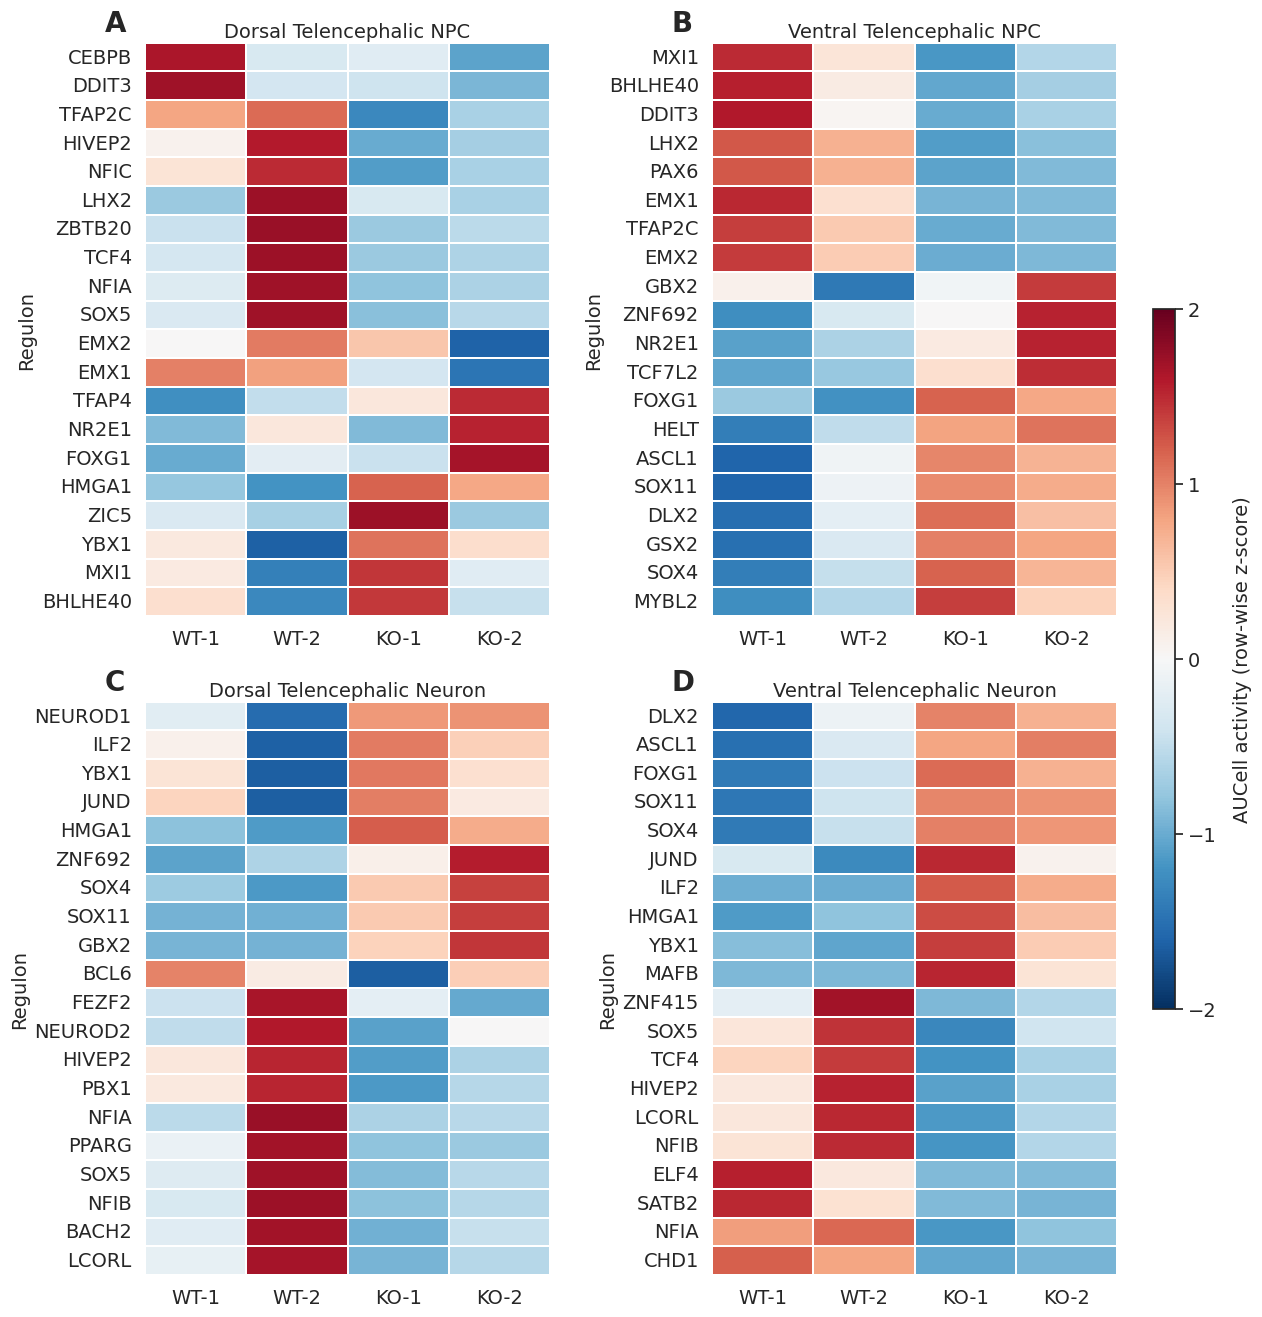

In [92]:
# PLOT 3: Dorsal to Ventral Shift Regulon activity
cell_types = ["Dorsal Telencephalic NPC", "Ventral Telencephalic NPC", "Dorsal Telencephalic Neuron", "Ventral Telencephalic Neuron"]
top_n = 20
group_order = [("NG", "WT"), ("JW", "WT"), ("NG", "KO"), ("JW", "KO")]
column_names = ["WT-1", "WT-2", "KO-1", "KO-2"]
font_size = 14

auc_name_map = {}
for col in auc_mtx.columns:
    clean = clean_regulon_name(col)
    if clean not in auc_name_map: auc_name_map[clean] = col

common_cells = auc_mtx.index.intersection(metadata.index)
auc_data = auc_mtx.loc[common_cells].copy().join(metadata.loc[common_cells,["CellType","Genotype","Sample"]])
sns.set_theme(style="white")
fig = plt.figure(figsize=(12,14))
outer = fig.add_gridspec(2,2,left=0.06,right=0.87,bottom=0.06,top=0.94,wspace=0.40,hspace=0.15)

for i,cell_type in enumerate(cell_types):
    row,col = divmod(i,2)
    ct_df = df[df["CellType"] == cell_type].copy()
    ct_df["Clean_Regulon"] = ct_df["Regulon"].apply(clean_regulon_name)
    regs = list(dict.fromkeys(r for r in ct_df["Clean_Regulon"].dropna() if r in auc_name_map))
    if not regs: print(f"No matching regulons found for {cell_type}"); continue
    ct_data = auc_data[auc_data["CellType"]==cell_type].copy()
    auc_columns = [auc_name_map[r] for r in regs]
    sample_means = ct_data.groupby(["Sample", "Genotype"])[auc_columns].mean().T
    sample_means.index = regs
    sample_means = sample_means.reindex(columns=pd.MultiIndex.from_tuples(group_order))
    sample_means.columns = column_names
    if sample_means.isna().all(axis=0).any(): print(f"Missing sample groups for {cell_type}"); continue
    delta = ((sample_means["KO-1"]-sample_means["WT-1"]) + (sample_means["KO-2"]-sample_means["WT-2"]))/2    
    top_regs = delta.abs().sort_values(ascending=False).head(top_n).index.tolist()
    heat = sample_means.loc[top_regs].copy()
    heat = heat.sub(heat.mean(axis=1),axis=0).div(heat.std(axis=1,ddof=0).replace(0,np.nan),axis=0).replace([np.inf,-np.inf],np.nan).dropna()
    if len(heat) >= 2: heat = heat.iloc[leaves_list(linkage(pdist(heat.values,metric="euclidean"),method="average"))]
    heat_ax = fig.add_subplot(outer[row,col])
    sns.heatmap(heat,ax=heat_ax,cmap="RdBu_r",vmin=-2,vmax=2,center=0,linewidths=0.2,linecolor="white",cbar=False)
    heat_ax.set_title(cell_type, fontsize=font_size, fontweight="normal", loc="center", pad=4)
    heat_ax.text(-0.1, 1.01, "ABCD"[i], transform=heat_ax.transAxes, fontsize=20, fontweight="bold", ha="left", va="bottom")
    heat_ax.set_xlabel(""); heat_ax.set_ylabel("Regulon",fontsize=font_size)
    heat_ax.tick_params(axis="x",labelrotation=0,labelsize=font_size); heat_ax.tick_params(axis="y",labelsize=font_size)
    heat_ax.set_yticklabels(heat_ax.get_yticklabels(),rotation=0,fontsize=font_size)
    heat_ax.set_xticklabels(heat_ax.get_xticklabels(),rotation=0,fontsize=font_size)

cbar_ax = fig.add_axes([0.90,0.25,0.018,0.50])
sm = plt.cm.ScalarMappable(cmap="RdBu_r",norm=plt.Normalize(-2,2)); sm.set_array([])
cbar = fig.colorbar(sm,cax=cbar_ax,ticks=[-2,-1,0,1,2])
cbar.set_label("AUCell activity (row-wise z-score)",fontsize=font_size,labelpad=12)
cbar.ax.tick_params(labelsize=font_size)

fig.savefig("SCENIC_regulon_heatmaps_4_cell_types.png",dpi=600,bbox_inches="tight",facecolor="white")
fig.savefig("SCENIC_regulon_heatmaps_4_cell_types.pdf",bbox_inches="tight",facecolor="white")
plt.show()

/scratch/pbs.9613716.kman.restech.unsw.edu.au/ipykernel_2307235/3179298084.py:63: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


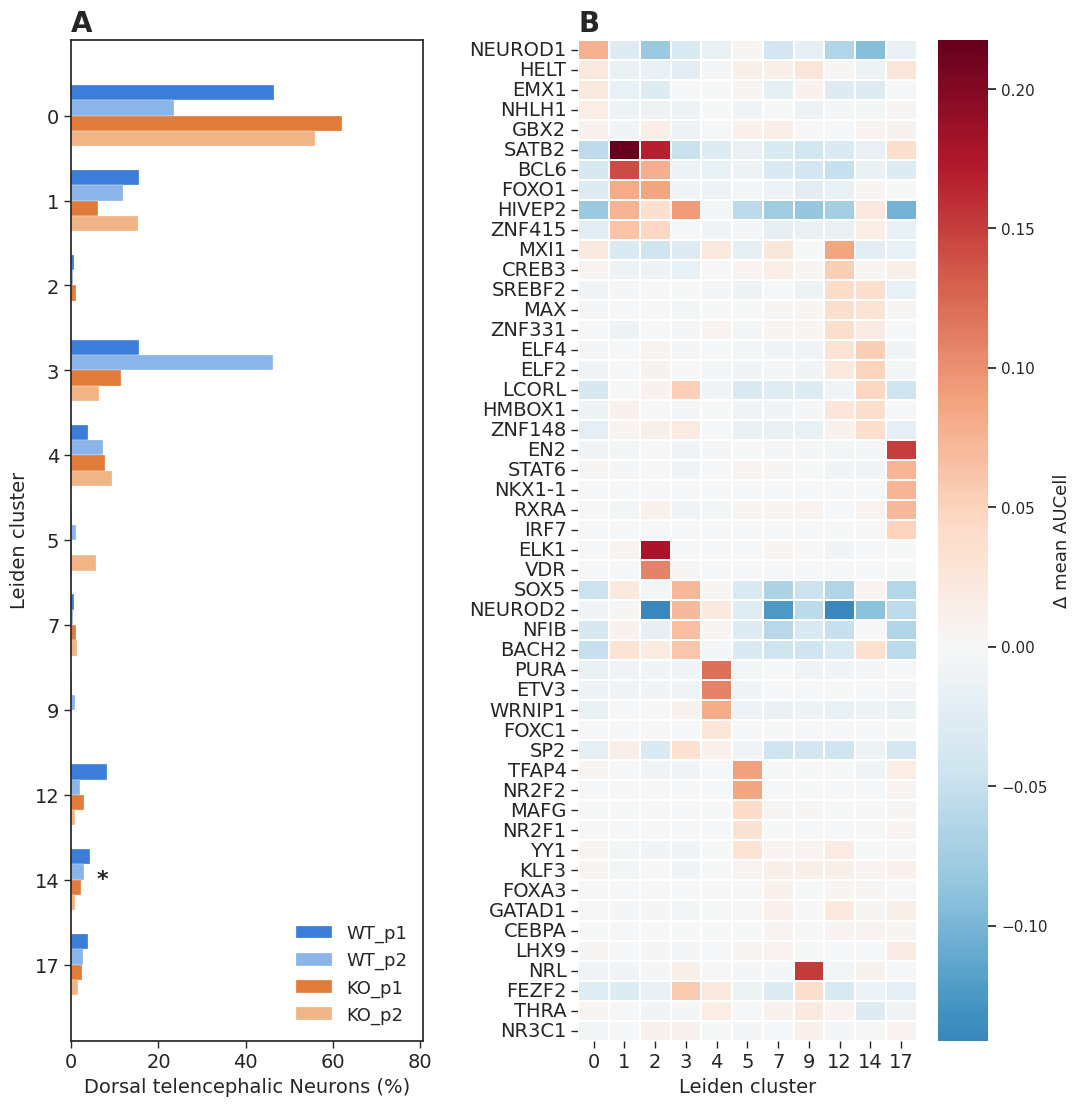

In [109]:
# PLOT: Heatmap + Cluster abundance with significance stars
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns

cell_type, top_n = "Dorsal telencephalic Neuron", 5
samples = ["WT_p1","WT_p2","KO_p1","KO_p2"]
palette = {"WT_p1":"#3b7dd8","WT_p2":"#8bb5e8","KO_p1":"#e07b39","KO_p2":"#f0b486"}

cells = auc_mtx.index.intersection(A.obs_names)
auc, obs = auc_mtx.loc[cells], A.obs.loc[cells].copy()
obs[["CellType","leiden"]] = obs[["CellType","leiden"]].astype(str)
wm = within_marker_regulons.reset_index()
wm[["CellType","cluster","regulon"]] = wm[["CellType","cluster","regulon"]].astype(str)
sub = wm[(wm.CellType.str.casefold()==cell_type.casefold()) & wm.regulon.isin(auc.columns)]
clusters = sorted(sub.cluster.unique(), key=int)
regs = list(dict.fromkeys(sub.sort_values(["cluster","diff"], ascending=[True,False]).groupby("cluster").head(top_n).regulon))
mask = obs.CellType.str.casefold()==cell_type.casefold()
auc_ct, obs_ct = auc.loc[mask], obs.loc[mask]

meta = metadata.copy(); meta.index = meta.index.astype(str)
meta["Sample"] = np.select([meta["orig.ident"].astype(str).str.startswith("p1") & meta.Genotype.eq("WT"), meta["orig.ident"].astype(str).str.startswith("p2") & meta.Genotype.eq("WT"),
                            meta["orig.ident"].astype(str).str.startswith("p1") & meta.Genotype.eq("KO"), meta["orig.ident"].astype(str).str.startswith("p2") & meta.Genotype.eq("KO")],
                           samples, default="UNKNOWN")
meta = meta.reindex(cells); meta[["CellType","leiden"]] = obs[["CellType","leiden"]]
ct = meta[(meta.CellType.str.casefold()==cell_type.casefold()) & meta.Sample.isin(samples)]
counts = pd.crosstab(ct.leiden,ct.Sample).reindex(index=clusters,columns=samples,fill_value=0)
pct = counts.div(ct.Sample.value_counts().reindex(samples,fill_value=0).replace(0,np.nan),axis=1).mul(100).fillna(0)
heat_b = pd.DataFrame({cl:{r:auc_ct.loc[obs_ct.leiden.eq(cl),r].mean()-auc_ct.loc[~obs_ct.leiden.eq(cl),r].mean() 
                           for r in regs if obs_ct.leiden.eq(cl).any() and (~obs_ct.leiden.eq(cl)).any()} for cl in clusters}).reindex(index=regs,columns=clusters)
heat_b.index = heat_b.index.str.replace("(+)","",regex=False)

# Load significant clusters
sig = pd.read_csv(out+"paired_ttest_all_celltypes.csv")
sig_clusters = set(sig.loc[sig.celltype.str.casefold().eq(cell_type.casefold()) & (sig.p_value < 0.05),"cluster"].astype(str))

# Create figure
fig, (ax1,ax2) = plt.subplots(1,2,figsize=(12,13),gridspec_kw={"width_ratios":[1,1.2],"wspace":0.4})
y,bh = np.arange(len(clusters)),0.18

# A: Cluster abundance
for i,s in enumerate(samples):
    ax1.barh(y+(i-1.5)*bh,pct[s],height=bh,color=palette[s],label=s,edgecolor="white",linewidth=0.2)
ax1.set_title("A",loc="left",fontsize=20,fontweight="bold")
ax1.set(yticks=y,yticklabels=clusters,ylabel="Leiden cluster",xlabel=f"{cell_type} cells (%)")
ax1.set_xlabel(f"{cell_type}s (%)", fontsize=14)
ax1.set_ylabel("Leiden cluster", fontsize=14)
ax1.invert_yaxis(); ax1.legend(frameon=False,fontsize=13,loc="best"); ax1.tick_params(labelsize=14)
ax1.set_xlim(0,max(1,pct.max().max())*1.3)
ax1.tick_params(axis="both", which="major", labelsize=14, length=5, width=1, direction="out", bottom=True, left=True)

# Stars inside the plot, after the longest bar in each significant cluster
for i,cl in enumerate(clusters):
    if cl in sig_clusters:
        ax1.text(pct.loc[cl].max()+1.5,y[i],"*",ha="left",va="center",fontsize=16,fontweight="bold",clip_on=True)

# B: Marker regulon activity
sns.heatmap(heat_b,ax=ax2,cmap="RdBu_r",center=0,linewidths=.05,linecolor="white",cbar_kws={"label":"Δ mean AUCell"})
ax2.set_title("B",loc="left",fontsize=20,fontweight="bold")
ax2.set(xlabel="Leiden cluster",ylabel=""); ax2.tick_params(axis="both",labelsize=14,rotation=0)
ax2.collections[0].colorbar.set_label("Δ mean AUCell",fontsize=13); ax2.collections[0].colorbar.ax.tick_params(labelsize=11)
ax2.set_xlabel("Leiden cluster", fontsize=14)
ax2.tick_params(axis="both", which="major", labelsize=14, length=5, width=1, direction="out", bottom=True, left=True)

plt.tight_layout()
plt.savefig(out + f"{cell_type.replace(' ', '_')}_heatmap_cluster_abundance.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# ============================================================
# WITHIN-CELL-TYPE MARKER REGULON RSS HEATMAPS
# Uses the SAME selected regulons as the AUCell-difference heatmaps
# ============================================================
# 1. Settings and imports
import os, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from matplotlib.backends.backend_pdf import PdfPages
from pyscenic.rss import regulon_specificity_scores

top_n=10
output_pdf="/srv/scratch/voineagu/PROJECTS/EvaVo/RESULTS/pasca_all_Preintegration/Hvg/all_celltypes_within_celltype_marker_regulons_RSS.pdf"

# 2. Prepare marker table and align cells
wm=within_marker_regulons.reset_index(); cell_types=wm["CellType"].dropna().unique().tolist()
common_cells=auc_mtx.index.intersection(A.obs_names); auc_plot=auc_mtx.loc[common_cells].copy(); obs_plot=A.obs.loc[common_cells].copy()
obs_plot["CellType"]=obs_plot["CellType"].astype(str); obs_plot["leiden"]=obs_plot["leiden"].astype(str)

# 3. Calculate RSS and plot one heatmap per cell type
os.makedirs(os.path.dirname(output_pdf),exist_ok=True)
with PdfPages(output_pdf) as pdf:
    for cell_type in cell_types:
        print(f"Processing {cell_type}")
        sub=wm[wm["CellType"]==cell_type].copy()
        top=sub.sort_values(["cluster","diff"],ascending=[True,False]).groupby("cluster",group_keys=False).head(top_n)
        clusters=sorted(sub["cluster"].astype(str).unique(),key=lambda x:int(x))
        selected_regulons=[r for r in top["regulon"].drop_duplicates() if r in auc_plot.columns]
        if not selected_regulons: print(f"No matching regulons for {cell_type}; skipping."); continue
        mask=obs_plot["CellType"]==cell_type; auc_ct=auc_plot.loc[mask]; obs_ct=obs_plot.loc[mask]
        if auc_ct.empty: print(f"No cells found for {cell_type}; skipping."); continue
        auc_for_rss=auc_ct[selected_regulons].copy(); cluster_labels=obs_ct.loc[auc_for_rss.index,"leiden"]
        valid=auc_for_rss.notna().all(axis=1); auc_for_rss=auc_for_rss.loc[valid]; cluster_labels=cluster_labels.loc[auc_for_rss.index]
        if auc_for_rss.empty: print(f"No valid AUCell scores for {cell_type}; skipping."); continue
        if (auc_for_rss<0).any().any(): raise ValueError(f"Negative AUCell values for {cell_type}; use unscaled, non-negative AUCell scores.")
        rss_df=pd.DataFrame(regulon_specificity_scores(auc_for_rss,cluster_labels)); rss_df.index=rss_df.index.astype(str); rss_df.columns=rss_df.columns.astype(str)

        # 4. Arrange RSS values to match the marker heatmap's regulon and cluster order
        clusters_present=[c for c in clusters if c in rss_df.index]
        regulons_present=[r for r in selected_regulons if r in rss_df.columns]
        heatmap_data=rss_df.loc[clusters_present,regulons_present].T.copy()
        top_order=top.sort_values(["cluster","diff"],ascending=[True,False])["regulon"].drop_duplicates().tolist()
        heatmap_data=heatmap_data.reindex([r for r in top_order if r in heatmap_data.index])
        heatmap_data.index=[str(r).replace("(+)","") for r in heatmap_data.index]
        if heatmap_data.empty: print(f"No RSS values to plot for {cell_type}; skipping."); continue

        # 5. Plot heatmap and adjust label sizes to the number of regulons
        n_rows=heatmap_data.shape[0]; y_fontsize=7.5 if n_rows<=40 else 6.5 if n_rows<=60 else 5.5 if n_rows<=80 else 4.5 if n_rows<=100 else 3.8
        fig,ax=plt.subplots(figsize=(8,8))
        sns.heatmap(heatmap_data,cmap="viridis",vmin=0,vmax=1,linewidths=0.25,linecolor="white",xticklabels=True,yticklabels=True,cbar_kws={"label":"Regulon specificity score (RSS)"},ax=ax)
        ax.set_xlabel("Leiden cluster",fontsize=9); ax.set_ylabel("Marker regulon",fontsize=9)
        ax.set_title(f"{cell_type}\nWithin-cell-type marker regulons (RSS)",fontsize=12,fontweight="bold",pad=10)
        plt.setp(ax.get_yticklabels(),rotation=0,fontsize=y_fontsize); plt.setp(ax.get_xticklabels(),rotation=0,fontsize=8)
        cbar=ax.collections[0].colorbar; cbar.ax.tick_params(labelsize=7); cbar.set_label("Regulon specificity score (RSS)",fontsize=8)
        fig.tight_layout(); pdf.savefig(fig,bbox_inches="tight"); plt.close(fig)
        print(f"Saved {cell_type}: {len(regulons_present)} regulons, {len(clusters_present)} clusters")

# 6. Confirm output
print("\nFinished RSS heatmaps.\nOutput:",output_pdf)

In [ ]:
# Making a table to compare the WT vs KO Leiden cluster sample
# Combine the metadata we need
meta = metadata.loc[A.obs_names].copy()
meta["CellType"] = A.obs["CellType"].astype(str)
meta["leiden"] = A.obs["leiden"].astype(str)
meta["Genotype"] = np.where(meta["orig.ident"].str.contains("KO"), "KO", "WT")
meta["Sample_label"] = np.select([meta["orig.ident"].str.startswith("p1") & (meta["Genotype"] == "WT"), meta["orig.ident"].str.startswith("p2") 
                                  & (meta["Genotype"] == "WT"), meta["orig.ident"].str.startswith("p1") & (meta["Genotype"] == "KO"), meta["orig.ident"].str.startswith("p2") 
                                  & (meta["Genotype"] == "KO")], ["WT_p1", "WT_p2", "KO_p1", "KO_p2"], default="UNKNOWN")
replicates = ["WT_p1", "WT_p2", "KO_p1", "KO_p2"]
rows = []
for celltype in sorted(meta["CellType"].unique()):
    ct_meta = meta[meta["CellType"] == celltype]
    clusters = sorted(ct_meta["leiden"].unique(), key=lambda x: int(x))
    for cluster in clusters:
        row = {"CellType": celltype, "Cluster": int(cluster)}
        for rep in replicates:
            rep_meta = ct_meta[ct_meta["Sample_label"] == rep]
            total_cells = len(rep_meta)
            cluster_cells = np.sum(rep_meta["leiden"] == cluster)
            row[rep] = 100 * cluster_cells / total_cells if total_cells > 0 else np.nan
        rows.append(row)

abundance = pd.DataFrame(rows)
abundance.head()
abundance["WT_mean"] = abundance[["WT_p1", "WT_p2"]].mean(axis=1)
abundance["KO_mean"] = abundance[["KO_p1", "KO_p2"]].mean(axis=1)

# KO - WT percentage-point difference
abundance["KO_minus_WT_pp"] = abundance["KO_mean"] - abundance["WT_mean"]
abundance["p1_difference"] = abundance["KO_p1"] - abundance["WT_p1"]
abundance["p2_difference"] = abundance["KO_p2"] - abundance["WT_p2"]
abundance["min_abundance"] = abundance[["WT_p1", "WT_p2", "KO_p1", "KO_p2"]].min(axis=1)
abundance["max_abundance"] = abundance[["WT_p1", "WT_p2", "KO_p1", "KO_p2"]].max(axis=1)

def concordance(row):
    d1, d2 = row["p1_difference"], row["p2_difference"]
    if pd.isna(d1) or pd.isna(d2): return "NA"
    if d1 > 0 and d2 > 0: return "KO_enriched_both"
    elif d1 < 0 and d2 < 0: return "WT_enriched_both"
    elif d1 == 0 and d2 == 0: return "No_difference"
    else: return "Discordant"

abundance["replicate_concordance"] = abundance.apply(concordance, axis=1)

def screening_category(row):
    effect, concordance = row["KO_minus_WT_pp"], row["replicate_concordance"]
    # Too rare to interpret robustly
    if all(row[col] < 5 for col in ["WT_p1", "WT_p2", "KO_p1", "KO_p2"]): return "Rare"
    # Consistent and reasonably large genotype difference
    if concordance == "KO_enriched_both" and effect >= 5: return "KO-enriched candidate"
    if concordance == "WT_enriched_both" and effect <= -5: return "WT-enriched candidate"
    # Direction consistent but smaller effect
    if concordance in ["KO_enriched_both", "WT_enriched_both"]: return "Consistent, smaller effect"
    # Opposite directions between replicates
    if concordance == "Discordant": return "Discordant"
    return "No strong difference"

abundance["screening_category"] = abundance.apply(screening_category, axis=1)

final_table = abundance[["CellType", "Cluster", "WT_p1", "WT_p2", "KO_p1", "KO_p2", "WT_mean", "KO_mean", "KO_minus_WT_pp", "p1_difference", "p2_difference", "replicate_concordance",
                         "min_abundance", "screening_category"]].copy()
numeric_cols = ["WT_p1", "WT_p2", "KO_p1", "KO_p2", "WT_mean", "KO_mean", "KO_minus_WT_pp", "p1_difference", "p2_difference", "min_abundance"]

#output_path = "/srv/scratch/voineagu/PROJECTS/EvaVo/RESULTS/pasca_all_Preintegration/Hvg/WT_KO_Leiden_cluster_abundance_comparison.csv"
#final_table.to_csv(output_path, index=False)

#print(f"Saved to: {output_path}")

In [ ]:
# [OLD CODE] Plotting UMAP: For SCENIC clusters
import matplotlib.pyplot as plt, matplotlib.cm as cm

U=A.obsm["X_umap"]; clusters=A.obs["leiden"].astype(str)
clusters_sorted=sorted(clusters.unique(),key=int)
cpal={cl:cm.tab20(i%20) if i<20 else cm.tab20b((i-20)%20) for i,cl in enumerate(clusters_sorted)}
fig,ax=plt.subplots(figsize=(7,6))
fig.subplots_adjust(right=0.78)
for cl in clusters_sorted:
    m=clusters==cl; ax.scatter(U[m,0],U[m,1],s=3,c=[cpal[cl]],linewidths=0,rasterized=True,label=cl)
ax.set(title="SCENIC cell states",xlabel="UMAP1",ylabel="UMAP2")
ax.legend(title="SCENIC cluster",bbox_to_anchor=(1.02,1),loc="upper left",frameon=False,fontsize=10,markerscale=3)
#plt.savefig("/srv/scratch/voineagu/PROJECTS/EvaVo/RESULTS/pasca_all_Preintegration/Hvg/UMAP_SCENIC_clusters_D60_23clusters.png",dpi=300,bbox_inches="tight")
plt.show()

# Plotting UMAP: Genotype
geno=A.obs["Genotype"].astype(str)
fig,ax=plt.subplots(figsize=(7,6))
fig.subplots_adjust(right=0.78)
for g in ["WT","KO"]:
    m=geno==g; ax.scatter(U[m,0],U[m,1],s=3,linewidths=0,rasterized=True,label=g)
ax.set(xlabel="UMAP1",ylabel="UMAP2")
ax.legend(title="Genotype",frameon=False,bbox_to_anchor=(1.02,1),loc="upper left",fontsize=12,markerscale=3)
#plt.savefig("/srv/scratch/voineagu/PROJECTS/EvaVo/RESULTS/pasca_all_Preintegration/Hvg/UMAP_genotype_D60.png",dpi=300,bbox_inches="tight")
plt.show()

# PLotting UMAP: Cell type distribution
celltype_order=["Neuroepithelium","Dorsal Telencephalic NPC","Dorsal Telencephalic IP","Dorsal Telencephalic Neuron","Ventral Telencephalic NPC","Ventral Telencephalic Neuron","Non-telencephalic NPC","Non-telencephalic Neuron","Radial glia","OPC","MC","NC Derivatives","CP"]
celltypes=A.obs["CellType"].astype(str)
cts=[ct for ct in celltype_order if ct in celltypes.unique()]
cts+= [ct for ct in celltypes.unique() if ct not in celltype_palette]
ct_pal={ct:celltype_palette.get(ct,"#808080") for ct in cts}
fig,ax=plt.subplots(figsize=(7,6))
fig.subplots_adjust(right=0.78)
for ct in cts:
    mask=(celltypes==ct).to_numpy()
    ax.scatter(U[mask,0],U[mask,1],s=3,c=[ct_pal[ct]],linewidths=0,rasterized=True,label=ct)
ax.set(xlabel="UMAP1",ylabel="UMAP2")
ax.legend(title="Cell Type",bbox_to_anchor=(1.02,1),loc="upper left",frameon=False,fontsize=12,markerscale=3,scatterpoints=1)
#plt.savefig("/srv/scratch/voineagu/PROJECTS/EvaVo/RESULTS/pasca_all_Preintegration/Hvg/UMAP_celltype_D60.png",dpi=300,bbox_inches="tight")
plt.show()

celltype_order=["Neuroepithelium","Dorsal Telencephalic NPC","Dorsal Telencephalic IP","Dorsal Telencephalic Neuron","Ventral Telencephalic NPC","Ventral Telencephalic Neuron","Non-telencephalic NPC","Non-telencephalic Neuron","Radial glia","OPC","MC","NC Derivatives","CP"]
meta=A.obs[["CellType","Genotype"]].dropna().copy()
meta["Genotype"]=meta["Genotype"].astype(str).str.upper()
meta=meta[meta["Genotype"].isin(["WT","KO"])]
counts=pd.crosstab(meta["Genotype"],meta["CellType"])
props=counts.div(counts.sum(axis=1),axis=0)*100
celltype_order=[ct for ct in celltype_order if ct in props.columns]
props=props.reindex(index=["WT","KO"],columns=celltype_order,fill_value=0)
fig,ax=plt.subplots(figsize=(10,7))
bottom=pd.Series(0.0,index=props.index)
for ct in celltype_order:
    ax.bar(props.index,props[ct],bottom=bottom,label=ct,color=celltype_palette[ct],width=0.65,edgecolor="white",linewidth=0.5)
    bottom+=props[ct]
ax.set_ylabel("Cells within genotype (%)")
ax.set_xlabel("Genotype")
ax.set_ylim(0,100)
ax.set_yticks(range(0,101,10))
ax.legend(title="Cell type",title_fontsize=12,bbox_to_anchor=(1.02,1),loc="upper left",fontsize=12,frameon=False)
ax.spines[["top","right"]].set_visible(False)
fig.tight_layout()
plt.show()

In [ ]:
# Plotting UMAP: Selected regulon and plotting its AUCell Activity
# 1. Prepare plotting dataframe from your annotated AnnData object
plot_df=A.obs[["Genotype","CellType"]].copy()
plot_df["UMAP1"]=A.obsm["X_umap"][:,0]
plot_df["UMAP2"]=A.obsm["X_umap"][:,1]

# 2. Add DLX2 regulon activity, aligning cells by name
chosen_regulon="DLX2"; chosen_regulon_auc_mtx=f"{chosen_regulon}(+)"
common=plot_df.index.intersection(auc_mtx.index)
plot_df=plot_df.loc[common].copy()
plot_df[chosen_regulon]=auc_mtx.loc[common,chosen_regulon_auc_mtx]

# 3. Shared colour scale and UMAP axes
vmin=plot_df[chosen_regulon].min(); vmax=plot_df[chosen_regulon].max()
xm=(plot_df["UMAP1"].max()-plot_df["UMAP1"].min())*0.02
ym=(plot_df["UMAP2"].max()-plot_df["UMAP2"].min())*0.02
xlim=(plot_df["UMAP1"].min()-xm,plot_df["UMAP1"].max()+xm)
ylim=(plot_df["UMAP2"].min()-ym,plot_df["UMAP2"].max()+ym)

# 4. Plot WT and KO side-by-side
fig=plt.figure(figsize=(14,6))
fig.patch.set_alpha(0)

# Fixed axes positions: [left, bottom, width, height]
ax1=fig.add_axes([0.05,0.12,0.32,0.76])
ax2=fig.add_axes([0.40,0.12,0.32,0.76])
cax=fig.add_axes([0.76,0.18,0.018,0.64])

for ax,g in zip([ax1,ax2],["WT","KO"]):
    d=plot_df[plot_df["Genotype"].astype(str)==g]
    sc=ax.scatter(d["UMAP1"],d["UMAP2"],c=d[chosen_regulon],s=3,cmap="RdYlBu_r",vmin=vmin,vmax=vmax,linewidths=0)
    ax.set(xlim=xlim,ylim=ylim,title=g,xlabel="UMAP1",ylabel="UMAP2")
    ax.set_box_aspect(459/459)  # Set equal panel dimensions

fig.colorbar(sc,cax=cax,label="AUCell score")
fig.suptitle(f"{chosen_regulon} Regulon Activity",fontsize=16,fontweight="bold")
plt.show()

In [ ]:
# Plotting Heat Map for the selected regulons
import re, os, numpy as np, pandas as pd, seaborn as sns, matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.backends.backend_pdf import PdfPages

def clean_regulon_name(name): return re.sub(r"_\d+$","",str(name).split("(")[0].strip())

selected_regulons=["GSX2","ASCL1","DLX2","LHX2","EMX1","EMX2","PAX6","SOX5","FEZF2","NFIB","NR2F1","NR2F2","GBX2","LHX1","LHX5","E2F1","E2F2","E2F3","E2F7","E2F8","FOXM1","MYBL2"]
regulon_groups={"Ventral progenitor/neurogenic":["GSX2","ASCL1","DLX2"],"Dorsal/cortical identity":["LHX2","EMX1","EMX2","PAX6"],"Cortical neuronal differentiation":["SOX5","FEZF2","NFIB"],"Regional neural patterning":["NR2F1","NR2F2","GBX2","LHX1","LHX5"],"Proliferation/cell cycle":["E2F1","E2F2","E2F3","E2F7","E2F8","FOXM1","MYBL2"]}
group_colours={"Ventral progenitor/neurogenic":"#d73027","Dorsal/cortical identity":"#4abcbd","Cortical neuronal differentiation":"#ba7bb4","Regional neural patterning":"#ebc74f","Proliferation/cell cycle":"#1a9850","Other":"#bdbdbd"}
regulon_to_group={r:g for g,regs in regulon_groups.items() for r in regs}

meta=metadata.copy()
meta["Genotype"]=np.where(meta["orig.ident"].astype(str).str.contains("KO",case=False),"KO","WT")
meta["Sample"]=np.select([meta["orig.ident"].astype(str).str.startswith("p1"),meta["orig.ident"].astype(str).str.startswith("p2")],["p1","p2"],default="Unknown")
common_cells=auc_mtx.index.intersection(meta.index)
auc_data=auc_mtx.loc[common_cells]
meta=meta.loc[common_cells]
auc_name_map={clean_regulon_name(c):c for c in auc_data.columns[::-1]}
found=[auc_name_map[r] for r in selected_regulons if r in auc_name_map]
print("Matched regulons:",[clean_regulon_name(r) for r in found])
print("Missing regulons:",[r for r in selected_regulons if r not in auc_name_map])
print("Cell counts:\n",meta.groupby(["Genotype","Sample"],observed=True).size())

group_order=[("WT","p1"),("WT","p2"),("KO","p1"),("KO","p2")]
column_names=["WT-p1","WT-p2","KO-p1","KO-p2"]
pdf_path="/srv/scratch/voineagu/PROJECTS/EvaVo/RESULTS/pasca_all_Preintegration/Hvg/selected_regulons_mean_AUCell_all_celltypes.pdf"
os.makedirs(os.path.dirname(pdf_path),exist_ok=True)

with PdfPages(pdf_path) as pdf:
    for ct in sorted(meta["CellType"].dropna().unique()):
        cell_idx=meta.index[meta["CellType"].eq(ct)]
        ct_data=auc_data.loc[cell_idx]
        if ct_data.empty or not found: continue
        ct_meta=meta.loc[cell_idx]
        heat=ct_data.groupby([ct_meta["Genotype"],ct_meta["Sample"]],observed=True)[found].mean().T
        heat=heat.reindex(columns=pd.MultiIndex.from_tuples(group_order))
        heat.columns=column_names
        if heat.dropna(how="all").empty: continue
        names=[clean_regulon_name(r) for r in heat.index]
        row_colours=[group_colours[regulon_to_group.get(n,"Other")] for n in names]
        fig=plt.figure(figsize=(13,8.27))
        # Fixed positions: heatmap, labels and colour bar are independent axes
        heat_ax=fig.add_axes([0.09,0.16,0.57,0.68])
        sns.heatmap(heat,cmap="RdBu_r",vmin=0,vmax=0.25,annot=True,fmt=".2f",linewidths=0.5,linecolor="white",ax=heat_ax,cbar=False,yticklabels=False)
        heat_ax.set_title(f"{ct}: Mean AUCell Activity",pad=12)
        heat_ax.set_xlabel("Sample",labelpad=8)
        heat_ax.set_ylabel("")
        heat_ax.tick_params(axis="y",left=False,right=True,length=4,width=0.8,labelleft=False,labelright=False)
        heat_ax.set_yticks(np.arange(len(heat.index))+0.5)
        # Group-colour strip flush against heatmap's left edge
        for i,c in enumerate(row_colours): heat_ax.add_patch(plt.Rectangle((-0.025,i),0.025,1,transform=heat_ax.get_yaxis_transform(),color=c,clip_on=False,lw=0))
        # Separate regulon-label axis: names are to the right of heatmap ticks
        label_ax=fig.add_axes([0.70,0.16,0.10,0.68])
        label_ax.set_xlim(0,1)
        label_ax.set_ylim(heat_ax.get_ylim())
        label_ax.set_yticks(np.arange(len(heat.index))+0.5)
        label_ax.set_yticklabels(names,fontsize=9)
        label_ax.yaxis.tick_left()
        label_ax.tick_params(axis="y",left=False,right=False,length=0,labelleft=True,labelright=False,pad=0)
        label_ax.set_xticks([])
        for spine in label_ax.spines.values(): spine.set_visible(False)
        # Vertical colour bar, closer to the regulon labels
        cbar_ax=fig.add_axes([0.73,0.28,0.018,0.44])
        fig.colorbar(heat_ax.collections[0],cax=cbar_ax,orientation="vertical",ticks=np.linspace(0,0.25,6))
        cbar_ax.set_ylabel("Mean AUCell activity",labelpad=7)
        # Horizontal group legend
        legend_handles=[Patch(facecolor=group_colours[g],label=g) for g in regulon_groups]
        legend_handles.append(Patch(facecolor=group_colours["Other"],label="Other"))
        fig.legend(handles=legend_handles,title="Regulon groups",loc="upper center",bbox_to_anchor=(0.48,0.98),ncol=3,frameon=False,fontsize=9,title_fontsize=10,columnspacing=1.2)
        pdf.savefig(fig)
        plt.close(fig)
# Regulon labels: place them clearly to the right of the heatmap tick marks

print(f"PDF saved to: {pdf_path}")

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, re
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

def clean_regulon_name(name): return re.sub(r"_\d+$","",str(name).split("(")[0].strip())

selected_regulons=["GSX2","ASCL1","DLX2","LHX2","EMX2","PAX6","SOX5","FEZF2","NFIB","NR2F1","NR2F2","GBX2","LHX1","LHX5","FOXM1","MYBL2"]
regulon_groups={"Ventral progenitor/neurogenic":["GSX2","ASCL1","DLX2"],"Dorsal/cortical identity":["LHX2","EMX2","PAX6"],"Cortical neuronal differentiation":["SOX5","FEZF2","NFIB"],"Regional neural patterning":["NR2F1","NR2F2","GBX2","LHX1","LHX5"],"Proliferation/cell cycle":["FOXM1","MYBL2"]}
group_colours={"Ventral progenitor/neurogenic":"#d73027","Dorsal/cortical identity":"#4abcbd","Cortical neuronal differentiation":"#ba7bb4","Regional neural patterning":"#ebc74f","Proliferation/cell cycle":"#1a9850"}
reg_order=[r for group in regulon_groups.values() for r in group]
meta=metadata.copy()
meta["Genotype"]=np.where(meta["orig.ident"].astype(str).str.contains("KO"),"KO","WT")
common_cells=auc_mtx.index.intersection(meta.index)
auc_data=auc_mtx.loc[common_cells]
meta=meta.loc[common_cells]
auc_name_map={clean_regulon_name(c):c for c in auc_data.columns[::-1]}
found=[r for r in reg_order if r in auc_name_map]
if not found: raise ValueError("None of the selected regulons were found in auc_mtx.")
cell_order=["Neuroepithelium","Radial glia","Dorsal Telencephalic NPC","Dorsal Telencephalic IP","Ventral Telencephalic NPC","Non-telencephalic NPC","Dorsal Telencephalic Neuron","Ventral Telencephalic Neuron","Non-telencephalic Neuron"]
cell_order=[ct for ct in cell_order if ct in meta["CellType"].dropna().unique()]
records=[]
for ct in cell_order:
    for genotype in ["WT","KO"]:
        idx=meta["CellType"].eq(ct)&meta["Genotype"].eq(genotype)
        for r in found:
            vals=auc_data.loc[idx,auc_name_map[r]].dropna()
            if len(vals): records.append({"CellType":ct,"Genotype":genotype,"Regulon":r,"MeanAUCell":vals.mean(),"Proportion":(vals>0.05).mean()})
plot_df=pd.DataFrame(records)
fig,axes=plt.subplots(1,2,figsize=(17,8),sharey=True)
norm=Normalize(vmin=0,vmax=max(0.25,plot_df["MeanAUCell"].max()))
for ax,genotype in zip(axes,["WT","KO"]):
    sub=plot_df[plot_df["Genotype"].eq(genotype)]
    for _,row in sub.iterrows():
        ax.scatter(cell_order.index(row["CellType"]),found.index(row["Regulon"]),s=20+180*row["Proportion"],c=[plt.cm.RdBu_r(norm(row["MeanAUCell"]))],edgecolors="grey",linewidths=0.25)
    ax.set_xticks(range(len(cell_order)))
    ax.set_xticklabels(cell_order,rotation=45,ha="right")
    ax.set_title(genotype,fontsize=13,fontweight="bold")
    ax.set_xlabel("Cell type")
    ax.grid(False)
axes[0].set_yticks(range(len(found)))
axes[0].set_yticklabels(found)
axes[0].set_ylabel("Regulon")
sm=ScalarMappable(norm=norm,cmap="RdBu_r")
fig.colorbar(sm,ax=axes.tolist(),label="Mean AUCell activity",shrink=0.75,pad=0.02)
fig.suptitle("Regulon Activity Across Cell Types: WT vs KO",fontsize=15,y=0.98)
fig.subplots_adjust(top=0.88,bottom=0.28,wspace=0.08,right=0.91)
plt.show()

In [ ]:
import matplotlib.pyplot as plt, matplotlib.cm as cm, numpy as np, os
from matplotlib.lines import Line2D
from matplotlib.backends.backend_pdf import PdfPages

# 1. Input and settings
obs=A.obs.copy(); U=A.obsm["X_umap"]; obs["leiden"]=obs["leiden"].astype(str); clusters=sorted(obs["leiden"].unique(),key=int)
cpal={cl:cm.tab20(i%20) if i<20 else cm.tab20b((i-20)%20) for i,cl in enumerate(clusters)}
geno_pal={"WT":"#3b7dd8","KO":"#e07b39"}; GREY="#dcdcdc"
cts=obs["CellType"].value_counts().index.tolist(); nWT=int((obs["Genotype"]=="WT").sum()); nKO=int((obs["Genotype"]=="KO").sum())
out_pdf="/srv/scratch/voineagu/PROJECTS/EvaVo/RESULTS/pasca_all_Preintegration/Hvg/celltype_cellstate_overview_D60_23clusters.pdf"
os.makedirs(os.path.dirname(out_pdf),exist_ok=True)

# 2. Generate one page per cell type
with PdfPages(out_pdf) as pdf:
    for ct in cts:
        mask=(obs["CellType"]==ct).values; clu=obs["leiden"].values; geno=obs["Genotype"].values
        present=[c for c in clusters if c in set(clu[mask])]
        fig=plt.figure(figsize=(11,9)); gs=fig.add_gridspec(2,2,height_ratios=[1.35,1],hspace=0.30,wspace=0.22)
        axA,axB,axC,axD=[fig.add_subplot(gs[i,j]) for i,j in [(0,0),(0,1),(1,0),(1,1)]]

        # a. UMAP by cluster
        axA.scatter(U[~mask,0],U[~mask,1],s=2,c=GREY,linewidths=0,rasterized=True)
        for cl in present:
            m=mask&(clu==cl); axA.scatter(U[m,0],U[m,1],s=5,c=[cpal[cl]],linewidths=0,rasterized=True)
        axA.legend(handles=[Line2D([],[],marker="o",linestyle="",markersize=4,color=cpal[c],label=c) for c in present],fontsize=5,ncol=2,frameon=False,loc="best",title="cluster",title_fontsize=6)
        axA.set_title("a  SCENIC clusters",fontsize=10,loc="left")

        # b. UMAP by genotype
        axB.scatter(U[~mask,0],U[~mask,1],s=2,c=GREY,linewidths=0,rasterized=True)
        for g in ["WT","KO"]:
            m=mask&(geno==g); axB.scatter(U[m,0],U[m,1],s=5,c=geno_pal[g],linewidths=0,rasterized=True,label=g)
        axB.legend(fontsize=8,frameon=False,markerscale=2); axB.set_title("b  genotype",fontsize=10,loc="left")
        for ax in [axA,axB]:
            ax.set(xticks=[],yticks=[],xlabel="UMAP1",ylabel="UMAP2"); ax.xaxis.label.set_size(7); ax.yaxis.label.set_size(7)

        # c. Cell-type proportion within each genotype
        xW=(mask&(geno=="WT")).sum()/nWT*100 if nWT else 0; xK=(mask&(geno=="KO")).sum()/nKO*100 if nKO else 0
        vals=[xW,xK]; axC.bar(["WT","KO"],vals,color=[geno_pal["WT"],geno_pal["KO"]],width=0.6)
        for i,v in enumerate(vals): axC.text(i,v,f"{v:.1f}%",ha="center",va="bottom",fontsize=9)
        axC.set_ylabel("% of genotype's cells that are\nthis cell type",fontsize=8); axC.set_ylim(0,max(vals)*1.2+1e-6)
        axC.set_title("c  cell-type proportion (WT vs KO)",fontsize=10,loc="left")

        # d. Cluster composition within each cell type
        xcells=obs[mask]; bottom={"WT":0.0,"KO":0.0}
        for cl in present:
            vals=[(gg["leiden"]==cl).sum()/max(len(gg),1)*100 for g in ["WT","KO"] for gg in [xcells[xcells["Genotype"]==g]]]
            axD.bar(["WT","KO"],vals,bottom=[bottom["WT"],bottom["KO"]],color=cpal[cl],width=0.6,edgecolor="white",linewidth=0.3)
            bottom["WT"]+=vals[0]; bottom["KO"]+=vals[1]
        axD.set(ylim=(0,100),ylabel="% of cell type's cells\nin each cluster")
        axD.yaxis.label.set_size(8); axD.set_title("d  cell-state composition (WT vs KO)",fontsize=10,loc="left")

        # Title and save
        nX_WT=int((mask&(geno=="WT")).sum()); nX_KO=int((mask&(geno=="KO")).sum())
        fig.suptitle(f"{ct}   (WT n={nX_WT}, KO n={nX_KO})",fontsize=14,fontweight="bold",x=0.02,ha="left")
        pdf.savefig(fig,dpi=150,bbox_inches="tight"); plt.close(fig)

print("Wrote:",out_pdf); print("Number of cell-type pages:",len(cts))

In [ ]:
# 1. Nature-style formatting and output settings
font = "Arial" if "Arial" in {f.name for f in font_manager.fontManager.ttflist} else "DejaVu Sans"
mpl.rcParams.update({"font.family":font,"font.size":8,"axes.labelsize":9,"axes.titlesize":12,"xtick.labelsize":8,"ytick.labelsize":8,"legend.fontsize":8,"axes.linewidth":0.7,"xtick.major.width":0.7,"ytick.major.width":0.7,"xtick.major.size":2.5,"ytick.major.size":2.5,"pdf.fonttype":42,"ps.fonttype":42,"savefig.facecolor":"white","figure.facecolor":"white","axes.facecolor":"white"})
sns.set_style("ticks")
top_n = 5
fixed_vmax = 0.23  # Shared colour scale across all cell types; adjust if values exceed this
output_pdf = "/srv/scratch/voineagu/PROJECTS/EvaVo/RESULTS/pasca_all_Preintegration/Hvg/all_celltypes_marker_heatmap_and_composition_Nature.pdf"
sample_order = ["WT_p1","WT_p2","KO_p1","KO_p2"]
sample_pal = {"WT_p1":"#3b7dd8","WT_p2":"#8bb5e8","KO_p1":"#e07b39","KO_p2":"#f0b486"}
os.makedirs(os.path.dirname(output_pdf), exist_ok=True)

# 2. Prepare regulon, AUCell and cell metadata
wm = within_marker_regulons.reset_index().copy()
wm["cluster"] = wm["cluster"].astype(str); wm["CellType"] = wm["CellType"].astype(str); wm["regulon"] = wm["regulon"].astype(str)
auc_plot = auc_mtx.copy(); auc_plot.index = auc_plot.index.astype(str)
obs_plot = A.obs.copy(); obs_plot.index = obs_plot.index.astype(str); obs_plot["CellType"] = obs_plot["CellType"].astype(str); obs_plot["leiden"] = obs_plot["leiden"].astype(str)
common_cells = auc_plot.index.intersection(obs_plot.index)
auc_plot = auc_plot.loc[common_cells]; obs_plot = obs_plot.loc[common_cells].copy()
meta = metadata.copy(); meta.index = meta.index.astype(str)
meta["Sample_label"] = np.select([meta["orig.ident"].astype(str).str.startswith("p1")&meta["Genotype"].astype(str).eq("WT"),meta["orig.ident"].astype(str).str.startswith("p2")&meta["Genotype"].astype(str).eq("WT"),meta["orig.ident"].astype(str).str.startswith("p1")&meta["Genotype"].astype(str).eq("KO"),meta["orig.ident"].astype(str).str.startswith("p2")&meta["Genotype"].astype(str).eq("KO")], sample_order, default="UNKNOWN")
meta = meta.reindex(common_cells); meta["CellType"] = obs_plot["CellType"]; meta["leiden"] = obs_plot["leiden"]
print("Font:",font,"| AUCell cells:",len(auc_plot),"| Recognised sample labels:",meta["Sample_label"].isin(sample_order).sum())
print(meta["Sample_label"].value_counts(dropna=False))
if meta["Sample_label"].isin(sample_order).sum() == 0: raise ValueError("No recognised sample labels. Check cell barcode alignment and orig.ident/Genotype values.")
cell_types = wm["CellType"].dropna().unique().tolist(); skipped = []; pages = 0

# 3. Generate one A4 landscape page per cell type in a single PDF
with PdfPages(output_pdf) as pdf:
    for cell_type in cell_types:
        print("Plotting:",cell_type)
        sub = wm[wm["CellType"] == cell_type].copy()
        top = sub.sort_values(["cluster","diff"],ascending=[True,False]).groupby("cluster",group_keys=False).head(top_n)
        regs = [r for r in top["regulon"].drop_duplicates() if r in auc_plot.columns]
        if not regs: skipped.append((cell_type,"No marker regulons in AUCell matrix")); continue
        ct = meta[meta["CellType"].eq(cell_type)&meta["Sample_label"].isin(sample_order)].copy()
        if ct.empty: skipped.append((cell_type,"No matching cells/sample labels")); continue
        ct_counts = ct["Sample_label"].value_counts().reindex(sample_order,fill_value=0)
        counts = pd.crosstab(ct["leiden"],ct["Sample_label"]).reindex(columns=sample_order,fill_value=0)
        marker_clusters = set(top["cluster"].astype(str).unique())
        clusters = sorted(marker_clusters.intersection(ct["leiden"].dropna().unique()),key=lambda z:(0,float(z)) if z.replace(".","",1).isdigit() else (1,z))
        counts = counts.reindex(index=clusters,columns=sample_order,fill_value=0)
        pct = counts.div(ct_counts.replace(0,np.nan),axis=1).mul(100).fillna(0)

        # 4. Calculate within-cell-type mean AUCell differences for each cluster
        mask = obs_plot["CellType"].eq(cell_type); auc_ct = auc_plot.loc[mask]; obs_ct = obs_plot.loc[mask]
        rows = []
        for cl in clusters:
            inside = obs_ct["leiden"].eq(cl); outside = ~inside
            if not inside.any() or not outside.any(): continue
            for r in regs: rows.append({"cluster":cl,"regulon":r,"diff":auc_ct.loc[inside,r].mean()-auc_ct.loc[outside,r].mean()})
        if not rows: skipped.append((cell_type,"No valid AUCell differences")); continue
        heat = pd.DataFrame(rows).pivot(index="regulon",columns="cluster",values="diff")
        clusters = [c for c in clusters if c in heat.columns and heat[c].notna().any()]
        if not clusters: skipped.append((cell_type,"No usable clusters")); continue
        heat = heat.reindex(columns=clusters); pct = pct.reindex(clusters)
        order = []
        for cl in clusters: order.extend([r for r in top.loc[top["cluster"].eq(cl)].sort_values("diff",ascending=False)["regulon"] if r in heat.index and r not in order])
        heat = heat.reindex(order).dropna(how="all"); heat.index = [str(r).replace("(+)","") for r in heat.index]
        if heat.empty: skipped.append((cell_type,"Empty heatmap")); continue

        # 5. A4 landscape layout with clear separation between panels
        nr, nc = heat.shape
        fig = plt.figure(figsize=(11.69,8.27))
        gs = fig.add_gridspec(2,2,width_ratios=[30,0.7],height_ratios=[max(nr,12),7],hspace=0.19,wspace=0.04,left=0.10,right=0.95,top=0.96,bottom=0.10)
        axh = fig.add_subplot(gs[0,0]); cax = fig.add_subplot(gs[0,1]); axb = fig.add_subplot(gs[1,0])

        # 6. Heatmap: fixed symmetric scale, white at zero, blue negative and red positive
        norm = TwoSlopeNorm(vmin=-fixed_vmax,vcenter=0,vmax=fixed_vmax)
        sns.heatmap(heat,cmap="RdBu_r",norm=norm,linewidths=0.2,linecolor="white",xticklabels=True,yticklabels=True,cbar=True,cbar_ax=cax,cbar_kws={"ticks":np.linspace(-fixed_vmax,fixed_vmax,5)},ax=axh)
        axh.set_title(cell_type,loc="center",fontsize=13,fontweight="bold",pad=6)
        axh.set_ylabel("Marker regulon",fontsize=10,labelpad=5); axh.set_xlabel("")
        axh.tick_params(axis="x",bottom=False,labelbottom=False,length=0)
        axh.tick_params(axis="y",labelsize=8,length=2.5,width=0.6,direction="out",pad=3)
        axh.set_yticklabels(axh.get_yticklabels(),rotation=0)
        axh.spines["left"].set_visible(False)
        for side in ["top","right","bottom"]: axh.spines[side].set_visible(False)
        axh.text(-0.085,1.0,"a)",transform=axh.transAxes,fontsize=11,fontweight="bold",va="top",ha="right",clip_on=False)

        # 7. Continuous colour bar with clean, consistent tick labels
        cax.set_ylabel("Δ mean AUCell",fontsize=9,labelpad=5)
        cax.tick_params(labelsize=8,length=2,width=0.6,pad=2)
        cax.yaxis.set_major_formatter(FormatStrFormatter("%.2f")

        # 8. Bar plot: sample composition with left and bottom axes only
        x = np.arange(len(clusters))+0.5
        bw = min(0.18,0.72/len(sample_order))
        offsets = dict(zip(sample_order,[-1.5*bw,-0.5*bw,0.5*bw,1.5*bw]))
        for s in sample_order: axb.bar(x+offsets[s],pct[s].values,width=bw,color=sample_pal[s],label=s,edgecolor="none")
        axb.set_xlim(0,len(clusters)); axb.set_xticks(x); axb.set_xticklabels(clusters,fontsize=8)
        axb.set_xlabel("Leiden cluster",fontsize=10,labelpad=4)
        axb.set_ylabel("% of cell-type cells\nper sample",fontsize=9,labelpad=3)
        axb.yaxis.set_label_coords(-0.045,0.5)
        axb.spines["top"].set_visible(False); axb.spines["right"].set_visible(False)
        axb.spines["left"].set_visible(True); axb.spines["bottom"].set_visible(True)
        axb.spines["left"].set_linewidth(0.7); axb.spines["bottom"].set_linewidth(0.7)
        axb.tick_params(axis="both",which="major",direction="out",length=3,width=0.7,pad=3,labelsize=8)
        axb.grid(False); axb.set_ylim(0,max(5,float(pct.to_numpy().max())*1.15))
        axb.legend(frameon=False,ncol=4,loc="lower center",bbox_to_anchor=(0.5,1.06),borderaxespad=0,columnspacing=1.4,handlelength=1.1,handletextpad=0.4,fontsize=8)
        axb.text(-0.085,1.04,"b)",transform=axb.transAxes,fontsize=11,fontweight="bold",va="bottom",ha="right",clip_on=False)

        # 9. Save each cell type as one page in the same PDF
        pdf.savefig(fig,facecolor="white")
        plt.close(fig); pages += 1

print("\nPDF complete:",output_pdf,"\nPages saved:",pages,"\nPDF exists:",os.path.exists(output_pdf))
if skipped: print("Skipped:",skipped)